In [1]:
import urllib.request

url = "https://archive.ics.uci.edu/static/public/231/pamap2+physical+activity+monitoring.zip"
download_path = "/content/PAMAP2_full.zip"

try:
    urllib.request.urlretrieve(url, download_path)

    import os
    import zipfile

    print("Downloaded size:", os.path.getsize(download_path), "bytes")
    print("Valid ZIP:", zipfile.is_zipfile(download_path))

except Exception as e:
    print("Download failed:", e)

Downloaded size: 688226940 bytes
Valid ZIP: True


In [2]:
import zipfile
import os

zip_path = "/content/PAMAP2_full.zip"
extract_dir = "/content/PAMAP2_Extracted"

if zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        print("Files in archive:", len(z.namelist()))
        z.extractall(extract_dir)

    print("Extraction successful!")
else:
    print("The downloaded file is still incomplete or invalid.")

Files in archive: 2
Extraction successful!


In [3]:
import os
import zipfile

inner_zip = "/content/PAMAP2_Extracted/PAMAP2_Dataset.zip"
extract_dir = "/content/PAMAP2_Data"

print("Inner ZIP exists:", os.path.exists(inner_zip))

if zipfile.is_zipfile(inner_zip):
    with zipfile.ZipFile(inner_zip, "r") as z:
        print("Files inside inner ZIP:", len(z.namelist()))
        print("First 15 entries:")
        print("\n".join(z.namelist()[:15]))
        z.extractall(extract_dir)

    print("\nExtraction completed!")
else:
    print("The inner file is not a valid ZIP archive.")

Inner ZIP exists: True
Files inside inner ZIP: 22
First 15 entries:
PAMAP2_Dataset/Protocol/subject101.dat
PAMAP2_Dataset/Protocol/subject102.dat
PAMAP2_Dataset/Protocol/subject103.dat
PAMAP2_Dataset/Protocol/subject104.dat
PAMAP2_Dataset/Protocol/subject105.dat
PAMAP2_Dataset/Protocol/subject106.dat
PAMAP2_Dataset/Protocol/subject107.dat
PAMAP2_Dataset/Protocol/subject108.dat
PAMAP2_Dataset/Protocol/subject109.dat
PAMAP2_Dataset/Optional/subject101.dat
PAMAP2_Dataset/Optional/subject105.dat
PAMAP2_Dataset/Optional/subject106.dat
PAMAP2_Dataset/Optional/subject108.dat
PAMAP2_Dataset/Optional/subject109.dat
PAMAP2_Dataset/PerformedActivitiesSummary.pdf

Extraction completed!


In [4]:
import glob
import os

data_dir = "/content/PAMAP2_Data/PAMAP2_Dataset/Protocol"

dat_files = sorted(
    glob.glob(os.path.join(data_dir, "subject*.dat"))
)

print("Number of Protocol subject files:", len(dat_files))

for f in dat_files:
    print(os.path.basename(f))

Number of Protocol subject files: 9
subject101.dat
subject102.dat
subject103.dat
subject104.dat
subject105.dat
subject106.dat
subject107.dat
subject108.dat
subject109.dat


In [5]:

from pathlib import Path
import pandas as pd
import numpy as np

PAMAP_PROTOCOL = Path(
    "/content/PAMAP2_Data/PAMAP2_Dataset/Protocol"
)

files = sorted(PAMAP_PROTOCOL.glob("subject*.dat"))

assert files, f"No PAMAP2 files found in {PAMAP_PROTOCOL}"

all_data = []

for file in files:
    df = pd.read_csv(file, sep=r"\s+", header=None)

    if df.shape[1] != 54:
        raise ValueError(
            f"{file.name} has {df.shape[1]} columns; expected 54."
        )

    # Preserve the subject ID separately as column 54.
    df["subject"] = file.stem.replace("subject", "")
    all_data.append(df)

print("Files loaded:", len(all_data))
print("First dataframe shape:", all_data[0].shape)
print("Subjects:", [df["subject"].iloc[0] for df in all_data])

data = pd.concat(all_data, ignore_index=True)

# Activity ID is original column 1.
activity = pd.to_numeric(data[1], errors="coerce")

# Hand IMU: 16g accelerometer XYZ + gyroscope XYZ.
sensor_cols = [4, 5, 6, 10, 11, 12]

X_raw = data[sensor_cols].apply(pd.to_numeric, errors="coerce")
X_raw.columns = [
    "hand_acc_x", "hand_acc_y", "hand_acc_z",
    "hand_gyro_x", "hand_gyro_y", "hand_gyro_z"
]

valid = activity.notna() & (activity != 0)

X_raw = X_raw.loc[valid].copy()
y_raw = activity.loc[valid].astype(int).copy()
subjects = data.loc[valid, "subject"].copy()

print("Sensor matrix:", X_raw.shape)
print("Activity labels:", sorted(y_raw.unique()))
print("Subjects:", sorted(subjects.unique()))
print("Missing sensor values:", X_raw.isna().sum().sum())


Files loaded: 9
First dataframe shape: (376417, 55)
Subjects: ['101', '102', '103', '104', '105', '106', '107', '108', '109']
Sensor matrix: (1942872, 6)
Activity labels: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(12), np.int64(13), np.int64(16), np.int64(17), np.int64(24)]
Subjects: ['101', '102', '103', '104', '105', '106', '107', '108', '109']
Missing sensor values: 66744


In [6]:

print("Data shape:", data.shape)
print("Columns:", data.columns.tolist())
print(data.head(3))

# Preserve the standard 54-column layout.
# Only rename if the activity and timestamp columns aren't already named.
if 0 in data.columns and 1 in data.columns:
    data = data.rename(columns={
        0: "timestamp",
        1: "activity_id",
        4: "acc_x",
        5: "acc_y",
        6: "acc_z",
        10: "gyro_x",
        11: "gyro_y",
        12: "gyro_z"
    })

print(data.columns.tolist()[:15])


Data shape: (2872533, 55)
Columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 'subject']
      0  1      2     3        4        5        6        7        8        9  \
0  8.38  0  104.0  30.0  2.37223  8.60074  3.51048  2.43954  8.76165  3.35465   
1  8.39  0    NaN  30.0  2.18837  8.56560  3.66179  2.39494  8.55081  3.64207   
2  8.40  0    NaN  30.0  2.37357  8.60107  3.54898  2.30514  8.53644  3.73280   

   ...        45        46       47       48       49   50   51   52   53  \
0  ...  0.009250 -0.017580 -61.1888 -38.9599 -58.1438  1.0  0.0  0.0  0.0   
1  ... -0.004638  0.000368 -59.8479 -38.8919 -58.5253  1.0  0.0  0.0  0.0   
2  ...  0.000148  0.022495 -60.7361 -39.4138 -58.3999  1.0  0.0  0.0  0.0   

   subject  
0      101  
1      101  
2      101  

[3 rows x 55 columns]
['timestamp', 'activity_id', 2, 3, 'ac

In [7]:

import numpy as np
import pandas as pd

WINDOW = 200
STRIDE = 100

# Use the named hand accelerometer columns created earlier.
acc_cols = ["acc_x", "acc_y", "acc_z"]

required = ["timestamp", "activity_id", "subject"] + acc_cols
missing = [c for c in required if c not in data.columns]
assert not missing, f"Missing columns: {missing}"

work = data[required].copy()

for col in ["timestamp", "activity_id"] + acc_cols:
    work[col] = pd.to_numeric(work[col], errors="coerce")

work = work.replace([np.inf, -np.inf], np.nan)
work = work.dropna(subset=required)
work = work[work["activity_id"] != 0].copy()
work["activity_id"] = work["activity_id"].astype(int)

work = work.sort_values(
    ["subject", "timestamp"]
).reset_index(drop=True)

def extract_acc_features(window):
    feats = []

    for j in range(3):
        s = window[:, j]
        feats.extend([
            s.mean(), s.std(), s.min(), s.max(),
            np.median(s),
            np.sqrt(np.mean(s ** 2)),
            np.mean(np.abs(np.diff(s)))
        ])

    mag = np.linalg.norm(window, axis=1)
    feats.extend([
        mag.mean(), mag.std(), mag.min(), mag.max(),
        np.sqrt(np.mean(mag ** 2)),
        np.mean(np.abs(np.diff(mag)))
    ])
    return feats

features, labels, groups = [], [], []

for subject_id, subject_df in work.groupby("subject", sort=True):
    subject_df = subject_df.reset_index(drop=True)
    activity = subject_df["activity_id"].to_numpy()
    sensor = subject_df[acc_cols].to_numpy(dtype=float)

    # Split into contiguous activity runs.
    run_start = 0
    for i in range(1, len(subject_df) + 1):
        boundary = (
            i == len(subject_df)
            or activity[i] != activity[i - 1]
        )

        if not boundary:
            continue

        run = sensor[run_start:i]
        label = int(activity[run_start])

        for start in range(0, len(run) - WINDOW + 1, STRIDE):
            window = run[start:start + WINDOW]
            if np.isfinite(window).all():
                features.append(extract_acc_features(window))
                labels.append(label)
                groups.append(str(subject_id))

        run_start = i

X_pamap = np.asarray(features, dtype=np.float32)
y_pamap = np.asarray(labels, dtype=int)
groups_pamap = np.asarray(groups)

print("PAMAP2 feature matrix:", X_pamap.shape)
print("Activity IDs:", np.unique(y_pamap))
print("Windows per subject:")
print(pd.Series(groups_pamap).value_counts().sort_index())


PAMAP2 feature matrix: (19156, 27)
Activity IDs: [ 1  2  3  4  5  6  7 12 13 16 17 24]
Windows per subject:
101    2465
102    2588
103    1722
104    2274
105    2688
106    2471
107    2295
108    2591
109      62
Name: count, dtype: int64


In [8]:
imu_cols = [
    "acc_x", "acc_y", "acc_z",
    "gyro_x", "gyro_y", "gyro_z"
]

n_before = len(data)

data = data.replace([np.inf, -np.inf], np.nan)

data = data.dropna(
    subset=["timestamp", "activity_id"] + imu_cols
).copy()

# Exclude transient activity ID 0
data = data[data["activity_id"] != 0].copy()

data["activity_id"] = data["activity_id"].astype(int)

data = data.sort_values(
    ["subject", "timestamp"]
).reset_index(drop=True)

print("Rows before cleaning:", n_before)
print("Rows after cleaning:", len(data))
print("Rows removed:", n_before - len(data))
print("Remaining missing values:", data[imu_cols].isna().sum().sum())
print("\nActivity counts:")
print(data["activity_id"].value_counts().sort_index())

Rows before cleaning: 2872533
Rows after cleaning: 1931748
Rows removed: 940785
Remaining missing values: 0

Activity counts:
activity_id
1     192498
2     185025
3     189777
4     232454
5      96668
6     164530
7     186114
12    117177
13    104927
16    175282
17    238462
24     48834
Name: count, dtype: int64


In [9]:

# Calculate time differences within each subject
data["dt"] = data.groupby("subject")["timestamp"].diff()

print("Timestamp difference statistics:")
print(data["dt"].describe(
    percentiles=[0.01, 0.50, 0.95, 0.99]
))

print("\nFirst 20 positive timestamp differences:")
print(
    data.loc[data["dt"] > 0, "dt"].head(20).to_list()
)

print("\nTimestamp difference counts:")
print("Zero or negative:", (data["dt"] <= 0).sum())
print("Greater than 0.05:", (data["dt"] > 0.05).sum())
print("Greater than 0.1:", (data["dt"] > 0.1).sum())

print("\nTime span by subject:")
print(
    data.groupby("subject")["timestamp"]
    .agg(["min", "max", "count"])
)


Timestamp difference statistics:
count    1.931739e+06
mean     1.418222e-02
std      7.841000e-01
min      1.000000e-02
1%       1.000000e-02
50%      1.000000e-02
95%      1.000000e-02
99%      1.000000e-02
max      4.299600e+02
Name: dt, dtype: float64

First 20 positive timestamp differences:
[0.010000000000005116, 0.00999999999999801, 0.00999999999999801, 0.010000000000005116, 0.00999999999999801, 0.00999999999999801, 0.00999999999999801, 0.010000000000005116, 0.00999999999999801, 0.00999999999999801, 0.010000000000005116, 0.00999999999999801, 0.00999999999999801, 0.00999999999999801, 0.010000000000005116, 0.00999999999999801, 0.00999999999999801, 0.010000000000005116, 0.00999999999999801, 0.00999999999999801]

Timestamp difference counts:
Zero or negative: 0
Greater than 0.05: 377
Greater than 0.1: 97

Time span by subject:
            min      max   count
subject                         
101       37.66  3626.37  248599
102       55.20  4245.68  260902
103      166.11  2443.19  

In [10]:

import numpy as np
import pandas as pd

WINDOW = 200
STRIDE = 100
GAP_THRESHOLD = 0.05  # seconds

imu_cols = [
    "acc_x", "acc_y", "acc_z",
    "gyro_x", "gyro_y", "gyro_z"
]

feature_rows = []
window_labels = []
window_subjects = []

# Work separately for each participant
for subject_id, subject_df in data.groupby("subject", sort=True):
    subject_df = subject_df.sort_values("timestamp").reset_index(drop=True)

    # Start a new segment at each activity change or timestamp gap
    activity_change = subject_df["activity_id"].ne(
        subject_df["activity_id"].shift()
    )

    timestamp_gap = subject_df["timestamp"].diff().gt(GAP_THRESHOLD)

    subject_df["segment"] = (
        activity_change | timestamp_gap
    ).cumsum()

    for _, segment_df in subject_df.groupby("segment", sort=False):
        if len(segment_df) < WINDOW:
            continue

        sensor_values = segment_df[imu_cols].to_numpy(dtype=np.float32)
        activity_id = int(segment_df["activity_id"].iloc[0])

        # Defensive check: only retain finite windows
        for start in range(0, len(sensor_values) - WINDOW + 1, STRIDE):
            window = sensor_values[start:start + WINDOW]

            if not np.isfinite(window).all():
                continue

            # Features: per-axis statistics
            features = []

            features.extend(window.mean(axis=0))
            features.extend(window.std(axis=0))
            features.extend(window.min(axis=0))
            features.extend(window.max(axis=0))
            features.extend(np.sqrt(np.mean(window ** 2, axis=0)))
            features.extend(np.percentile(window, 25, axis=0))
            features.extend(np.percentile(window, 75, axis=0))

            # Acceleration and angular-velocity magnitudes
            acc_mag = np.linalg.norm(window[:, :3], axis=1)
            gyro_mag = np.linalg.norm(window[:, 3:], axis=1)

            for magnitude in (acc_mag, gyro_mag):
                features.extend([
                    magnitude.mean(),
                    magnitude.std(),
                    magnitude.min(),
                    magnitude.max()
                ])

            feature_rows.append(features)
            window_labels.append(activity_id)
            window_subjects.append(subject_id)

feature_names = (
    [f"{stat}_{axis}" for stat in
     ["mean", "std", "min", "max", "rms", "p25", "p75"]
     for axis in imu_cols]
    + [
        f"{stat}_{sensor}_magnitude"
        for sensor in ["acc", "gyro"]
        for stat in ["mean", "std", "min", "max"]
    ]
)

X = pd.DataFrame(feature_rows, columns=feature_names)
y = np.asarray(window_labels, dtype=int)
groups = np.asarray(window_subjects, dtype=int)

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of participants:", len(np.unique(groups)))
print("\nWindows per activity:")
print(pd.Series(y).value_counts().sort_index())
print("\nWindows per participant:")
print(pd.Series(groups).value_counts().sort_index())
print("\nMissing feature values:", X.isna().sum().sum())
print("Non-finite feature values:", (~np.isfinite(X.to_numpy())).sum())


Feature matrix shape: (18835, 50)
Labels shape: (18835,)
Number of participants: 9

Windows per activity:
1     1913
2     1826
3     1875
4     2122
5      925
6     1633
7     1798
12    1149
13    1023
16    1741
17    2362
24     468
Name: count, dtype: int64

Windows per participant:
101    2440
102    2527
103    1714
104    2187
105    2635
106    2441
107    2251
108    2578
109      62
Name: count, dtype: int64

Missing feature values: 0
Non-finite feature values: 0


In [11]:
import numpy as np

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Groups shape:", groups.shape)

assert len(X) == len(y) == len(groups), \
    "Number of windows, labels, and subjects must match."

assert X.shape[1] == 50, \
    f"Expected 50 features, but got {X.shape[1]}."

assert np.isfinite(X.to_numpy()).all(), \
    "Features contain NaN or infinite values."

print("\nPreprocessing validation passed!")
print("Total windows:", len(X))
print("Features per window:", X.shape[1])
print("Activity classes:", np.unique(y))
print("Participants:", np.unique(groups))

Feature matrix shape: (18835, 50)
Labels shape: (18835,)
Groups shape: (18835,)

Preprocessing validation passed!
Total windows: 18835
Features per window: 50
Activity classes: [ 1  2  3  4  5  6  7 12 13 16 17 24]
Participants: [101 102 103 104 105 106 107 108 109]


In [12]:
import pandas as pd

activity_names = {
    1: "Lying",
    2: "Sitting",
    3: "Standing",
    4: "Walking",
    5: "Running",
    6: "Cycling",
    7: "Nordic walking",
    12: "Ascending stairs",
    13: "Descending stairs",
    16: "Vacuum cleaning",
    17: "Ironing",
    24: "Jump rope"
}

counts = pd.Series(y).value_counts().sort_index()

balance = pd.DataFrame({
    "activity_id": counts.index,
    "activity": [activity_names.get(i, "Unknown") for i in counts.index],
    "windows": counts.values,
    "percentage": (counts.values / len(y) * 100).round(2)
})

display(balance)

,activity_id,activity,windows,percentage
0,1,Lying,1913,10.16
1,2,Sitting,1826,9.69
2,3,Standing,1875,9.95
3,4,Walking,2122,11.27
4,5,Running,925,4.91
5,6,Cycling,1633,8.67
6,7,Nordic walking,1798,9.55
7,12,Ascending stairs,1149,6.10
8,13,Descending stairs,1023,5.43
9,16,Vacuum cleaning,1741,9.24


In [13]:
subject_counts = pd.Series(groups).value_counts().sort_index()

print("Windows per participant:")
display(subject_counts.to_frame("windows"))

print("Total participants:", len(subject_counts))
print("Smallest participant window count:", subject_counts.min())
print("Largest participant window count:", subject_counts.max())

Windows per participant:


,windows
101,2440
102,2527
103,1714
104,2187
105,2635
106,2441
107,2251
108,2578
109,62


Total participants: 9
Smallest participant window count: 62
Largest participant window count: 2635


In [14]:
import os
import numpy as np

OUTPUT_DIR = "/content/preprocessed_activity"
os.makedirs(OUTPUT_DIR, exist_ok=True)

np.savez_compressed(
    os.path.join(OUTPUT_DIR, "pamap2_hand_imu_windows.npz"),
    X=X.to_numpy(dtype=np.float32),
    y=y,
    groups=groups,
    feature_names=np.array(X.columns)
)

print("Saved preprocessed dataset.")
print("Location:",
      os.path.join(OUTPUT_DIR, "pamap2_hand_imu_windows.npz"))

Saved preprocessed dataset.
Location: /content/preprocessed_activity/pamap2_hand_imu_windows.npz


In [15]:

from sklearn.model_selection import GroupShuffleSplit
import numpy as np

# 75% of participants for training, 25% for testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y[train_idx]
y_test = y[test_idx]

groups_train = groups[train_idx]
groups_test = groups[test_idx]

print("Training participants:", np.unique(groups_train))
print("Testing participants:", np.unique(groups_test))

print("\nTraining windows:", len(X_train))
print("Testing windows:", len(X_test))

# Verify there is no participant overlap
overlap = set(groups_train) & set(groups_test)
assert len(overlap) == 0, f"Participant leakage: {overlap}"

print("\nParticipant separation check passed.")
print("Training activity IDs:", np.unique(y_train))
print("Testing activity IDs:", np.unique(y_test))

missing_test_classes = sorted(set(np.unique(y_train)) - set(np.unique(y_test)))
print("Classes in training but absent from test:", missing_test_classes)
# Inspect feature ranges using training data only
feature_check = X_train.describe().T[
    ["mean", "std", "min", "max"]
]

display(feature_check)

# Find constant or nearly constant features
constant_features = X_train.columns[
    X_train.nunique() <= 1
].tolist()

print("Constant features:", constant_features)

# Verify all feature values are finite
print("Training data finite:", np.isfinite(X_train.to_numpy()).all())
print("Test data finite:", np.isfinite(X_test.to_numpy()).all())

Training participants: [101 103 104 105 107 109]
Testing participants: [102 106 108]

Training windows: 11289
Testing windows: 7546

Participant separation check passed.
Training activity IDs: [ 1  2  3  4  5  6  7 12 13 16 17 24]
Testing activity IDs: [ 1  2  3  4  5  6  7 12 13 16 17 24]
Classes in training but absent from test: []


,mean,std,min,max
mean_acc_x,-4.759404,4.629569,-30.316872,9.276443
mean_acc_y,4.787464,3.013403,-9.730636,18.430439
mean_acc_z,3.835499,3.015656,-8.397571,9.582288
mean_gyro_x,0.009930,0.302544,-1.998762,2.188738
mean_gyro_y,0.025287,0.230194,-1.581447,1.651085
mean_gyro_z,0.004494,0.266796,-1.669585,1.593844
std_acc_x,2.523000,2.485185,0.048385,32.514668
std_acc_y,2.822200,3.534938,0.051811,36.055328
std_acc_z,1.727244,1.458825,0.079660,14.907459
std_gyro_x,0.871057,0.758539,0.018196,9.464276


Constant features: []
Training data finite: True
Test data finite: True


In [17]:

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Keep only the five core activities:
# 1 = Lying, 2 = Sitting, 3 = Standing,
# 4 = Walking, 5 = Running
selected_ids = [1, 2, 3, 4, 5]

mask = np.isin(y, selected_ids)

X_core = X.loc[mask].reset_index(drop=True)
y_core = y[mask]
groups_core = groups[mask]

print("Core dataset shape:", X_core.shape)
print("\nActivity counts:")
print(pd.Series(y_core).value_counts().sort_index())

# Split by participant to avoid data leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_core, y_core, groups=groups_core)
)

X_train_core = X_core.iloc[train_idx]
X_test_core = X_core.iloc[test_idx]

y_train_core = y_core[train_idx]
y_test_core = y_core[test_idx]

groups_train_core = groups_core[train_idx]
groups_test_core = groups_core[test_idx]

assert set(groups_train_core).isdisjoint(set(groups_test_core))

print("\nTraining participants:", np.unique(groups_train_core))
print("Testing participants:", np.unique(groups_test_core))
print("Training windows:", len(y_train_core))
print("Testing windows:", len(y_test_core))
print("Participant leakage: none")


Core dataset shape: (8661, 50)

Activity counts:
1    1913
2    1826
3    1875
4    2122
5     925
Name: count, dtype: int64

Training participants: [101 103 104 105 107 108]
Testing participants: [102 106]
Training windows: 6422
Testing windows: 2239
Participant leakage: none


In [18]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_core, y_core, groups=groups_core)
)

X_train_core = X_core.iloc[train_idx]
X_test_core = X_core.iloc[test_idx]

y_train_core = y_core[train_idx]
y_test_core = y_core[test_idx]

groups_train_core = groups_core[train_idx]
groups_test_core = groups_core[test_idx]

assert set(groups_train_core).isdisjoint(set(groups_test_core))

print("Train participants:", np.unique(groups_train_core))
print("Test participants:", np.unique(groups_test_core))
print("Train windows:", len(y_train_core))
print("Test windows:", len(y_test_core))

Train participants: [101 103 104 105 107 108]
Test participants: [102 106]
Train windows: 6422
Test windows: 2239


Filtered feature shape: (12934, 50)
Filtered label shape: (12934,)
Classes present: [1, 2, 3, 4, 5, 6, 12, 13, 24]
Participants: [101, 102, 103, 104, 105, 106, 107, 108, 109]
Train participants: [101, 103, 104, 105, 107, 109]
Test participants: [102, 106, 108]

Accuracy: 0.8214
Macro F1: 0.815
Weighted F1: 0.8267

Classification report:
                   precision    recall  f1-score   support

            Lying       0.92      0.92      0.92       705
          Sitting       0.86      0.81      0.84       674
         Standing       0.83      0.77      0.80       741
          Walking       0.89      0.78      0.83       847
          Running       0.99      0.92      0.95       453
          Cycling       0.86      0.86      0.86       706
 Ascending stairs       0.53      0.73      0.61       415
Descending stairs       0.60      0.78      0.68       352
        Jump rope       0.95      0.76      0.84       207

         accuracy                           0.82      5100
        ma

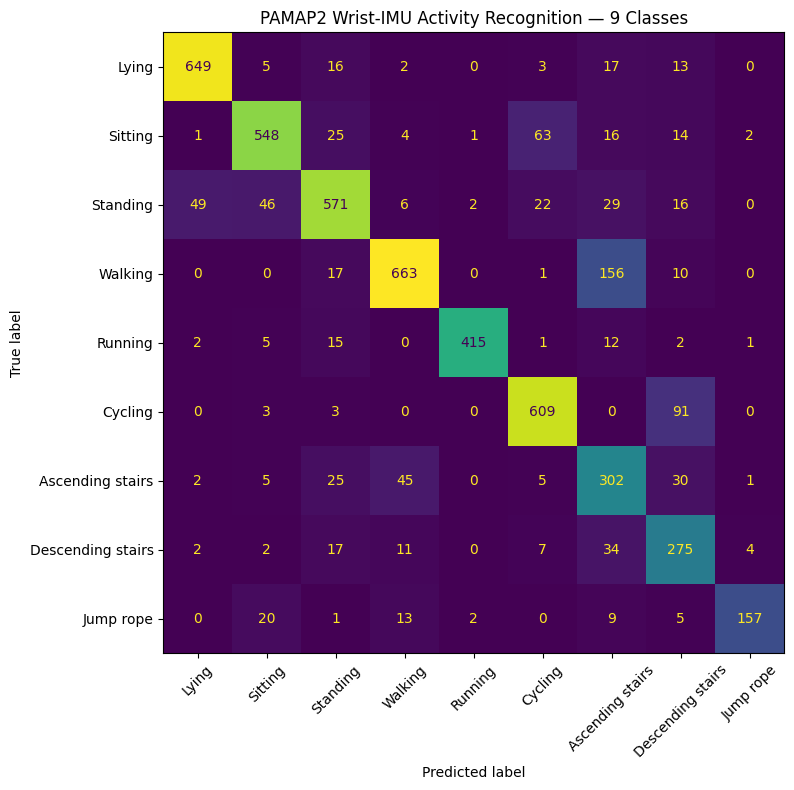

In [19]:

import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt

# Keep nine activity classes; exclude Nordic walking and household activities
selected_ids = [1, 2, 3, 4, 5, 6, 12, 13, 24]

activity_names = {
    1: "Lying",
    2: "Sitting",
    3: "Standing",
    4: "Walking",
    5: "Running",
    6: "Cycling",
    12: "Ascending stairs",
    13: "Descending stairs",
    24: "Jump rope"
}

# Filter the existing windowed features and labels
mask = np.isin(y, selected_ids)
X9 = X[mask]
y9 = y[mask]
groups9 = groups[mask]

print("Filtered feature shape:", X9.shape)
print("Filtered label shape:", y9.shape)
print("Classes present:", sorted(np.unique(y9).tolist()))
print("Participants:", sorted(np.unique(groups9).tolist()))

# Participant-independent train/test split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X9, y9, groups=groups9)
)

# Select rows by position, not columns
X_train = X9.iloc[train_idx]
X_test  = X9.iloc[test_idx]

y_train = np.asarray(y9)[train_idx]
y_test  = np.asarray(y9)[test_idx]


print("Train participants:", sorted(np.unique(groups9[train_idx]).tolist()))
print("Test participants:", sorted(np.unique(groups9[test_idx]).tolist()))

# Train Random Forest baseline
model9 = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced_subsample",
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model9.fit(X_train, y_train)
y_pred = model9.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print("Weighted F1:", round(f1_score(y_test, y_pred, average="weighted"), 4))

labels_present = sorted(np.unique(y9).tolist())
target_names = [activity_names[i] for i in labels_present]

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=labels_present,
    target_names=target_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=labels_present)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names
).plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
plt.title("PAMAP2 Wrist-IMU Activity Recognition — 9 Classes")
plt.tight_layout()
plt.show()


In [20]:

import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=labels_present)

cm_df = pd.DataFrame(
    cm,
    index=[activity_names[i] for i in labels_present],
    columns=[activity_names[i] for i in labels_present]
)


from IPython.display import display as show_table
show_table(cm_df)


,Lying,Sitting,Standing,Walking,Running,Cycling,Ascending stairs,Descending stairs,Jump rope
Lying,649,5,16,2,0,3,17,13,0
Sitting,1,548,25,4,1,63,16,14,2
Standing,49,46,571,6,2,22,29,16,0
Walking,0,0,17,663,0,1,156,10,0
Running,2,5,15,0,415,1,12,2,1
Cycling,0,3,3,0,0,609,0,91,0
Ascending stairs,2,5,25,45,0,5,302,30,1
Descending stairs,2,2,17,11,0,7,34,275,4
Jump rope,0,20,1,13,2,0,9,5,157


In [21]:

from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd

# Base models: tree ensembles plus nonlinear SVM
stack_estimators = [
    ("rf", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        min_samples_leaf=4,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )),
    ("hgb", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=44
    )),
    ("svm", make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=3.0,
            gamma="scale",
            class_weight="balanced",
            probability=True,
            random_state=45
        )
    ))
]

stack_model = StackingClassifier(
    estimators=stack_estimators,
    final_estimator=LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    stack_method="predict_proba",
    cv=3,
    n_jobs=-1
)

stack_model.fit(X_train, y_train)
stack_pred = stack_model.predict(X_test)

print("Stacking accuracy:",
      round(accuracy_score(y_test, stack_pred), 4))
print("Stacking macro F1:",
      round(f1_score(y_test, stack_pred, average="macro"), 4))
print("Stacking weighted F1:",
      round(f1_score(y_test, stack_pred, average="weighted"), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    stack_pred,
    labels=stack_model.classes_,
    target_names=[
        activity_names[int(i)] for i in stack_model.classes_
    ],
    zero_division=0
))


Stacking accuracy: 0.75
Stacking macro F1: 0.6907
Stacking weighted F1: 0.7489

Classification report:
                   precision    recall  f1-score   support

            Lying       0.92      0.90      0.91       705
          Sitting       0.78      0.85      0.82       674
         Standing       0.83      0.75      0.79       741
          Walking       0.90      0.80      0.85       847
          Running       0.97      0.20      0.33       453
          Cycling       0.89      0.84      0.87       706
 Ascending stairs       0.53      0.70      0.61       415
Descending stairs       0.57      0.77      0.66       352
        Jump rope       0.28      0.64      0.39       207

         accuracy                           0.75      5100
        macro avg       0.74      0.72      0.69      5100
     weighted avg       0.80      0.75      0.75      5100



In [22]:

import requests
from pathlib import Path

url = "https://zenodo.org/api/records/10013090/files/full_dataset.zip/content"
zip_path = Path("/content/full_dataset.zip")
expected_size = 26396425

response = requests.get(url, timeout=120)
response.raise_for_status()

zip_path.write_bytes(response.content)

actual_size = zip_path.stat().st_size
print("Downloaded size:", actual_size, "bytes")
print("Expected size:", expected_size, "bytes")
print("Size matches:", actual_size == expected_size)


Downloaded size: 26396425 bytes
Expected size: 26396425 bytes
Size matches: True


In [23]:

import zipfile
from pathlib import Path

zip_path = Path("/content/full_dataset.zip")
extract_dir = Path("/content/BITS-2")

print("Valid ZIP:", zipfile.is_zipfile(zip_path))

if not zipfile.is_zipfile(zip_path):
    raise ValueError("Download is not a valid ZIP. Do not extract it.")

extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    print("Archive entries:", len(z.namelist()))
    z.extractall(extract_dir)

print("\nExtracted files:")
for p in sorted(extract_dir.rglob("*")):
    if p.is_file():
        print(p.relative_to(extract_dir), "|", p.stat().st_size, "bytes")

from pathlib import Path
import pandas as pd

BITS_DIR = Path("/content/BITS-2")

print("Top-level folders:")
for p in BITS_DIR.iterdir():
    print(p.name)

# Locate sample activity and fall files
adl_files = list(BITS_DIR.rglob("*adl1.csv"))
fall_files = list(BITS_DIR.rglob("*fall1.csv"))

print("\nSample ADL files:", len(adl_files))
print("Sample fall files:", len(fall_files))

for label, files in [("ADL", adl_files), ("FALL", fall_files)]:
    if files:
        path = files[0]
        df = pd.read_csv(path)

        print(f"\n--- {label}: {path} ---")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head())
        print(df.dtypes)


Valid ZIP: True
Archive entries: 1068

Extracted files:
Dataset/adl/user1/user1_adl1.csv | 53532 bytes
Dataset/adl/user1/user1_adl10.csv | 10284 bytes
Dataset/adl/user1/user1_adl11.csv | 7126 bytes
Dataset/adl/user1/user1_adl12.csv | 24133 bytes
Dataset/adl/user1/user1_adl13.csv | 33555 bytes
Dataset/adl/user1/user1_adl14.csv | 3637 bytes
Dataset/adl/user1/user1_adl15.csv | 7419 bytes
Dataset/adl/user1/user1_adl16.csv | 6122 bytes
Dataset/adl/user1/user1_adl2.csv | 45890 bytes
Dataset/adl/user1/user1_adl3.csv | 11374 bytes
Dataset/adl/user1/user1_adl4.csv | 7655 bytes
Dataset/adl/user1/user1_adl5.csv | 41957 bytes
Dataset/adl/user1/user1_adl6.csv | 7175 bytes
Dataset/adl/user1/user1_adl7.csv | 4097 bytes
Dataset/adl/user1/user1_adl8.csv | 11967 bytes
Dataset/adl/user1/user1_adl9.csv | 19471 bytes
Dataset/adl/user10/user10_adl1.csv | 364697 bytes
Dataset/adl/user10/user10_adl10.csv | 99267 bytes
Dataset/adl/user10/user10_adl11.csv | 206805 bytes
Dataset/adl/user10/user10_adl12.csv | 126

In [24]:

from pathlib import Path
import pandas as pd
import numpy as np

BITS_DIR = Path("/content/BITS-2")  # Change if your extracted folder differs

files = list(BITS_DIR.rglob("*.csv"))
print("Total CSV files:", len(files))

recordings = []
metadata_values = {}
timestamp_samples = {}

for path in files:
    try:
        df = pd.read_csv(path)

        # Convert sensor axes and timestamps to numeric for inspection
        for col in ["t", "x", "y", "z"]:
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors="coerce")

        sensor_col = "Unnamed: 5" if "Unnamed: 5" in df.columns else None
        sensor_types = (
            sorted(df[sensor_col].dropna().astype(str).unique().tolist())
            if sensor_col else []
        )

        recordings.append({
            "file": str(path.relative_to(BITS_DIR)),
            "rows": len(df),
            "columns": len(df.columns),
            "sensor_types": ",".join(sensor_types),
            "bad_t": df["t"].isna().sum() if "t" in df else None,
            "bad_x": df["x"].isna().sum() if "x" in df else None,
            "bad_y": df["y"].isna().sum() if "y" in df else None,
            "bad_z": df["z"].isna().sum() if "z" in df else None,
            "a_values": ",".join(
                df["a"].dropna().astype(str).unique()[:10]
            ) if "a" in df else "",
        })

        if sensor_col:
            metadata_values.setdefault(sensor_col, set()).update(
                df[sensor_col].dropna().astype(str).unique()
            )
        if "a" in df:
            metadata_values.setdefault("a", set()).update(
                df["a"].dropna().astype(str).unique()
            )

        if "t" in df:
            t = df["t"].dropna().to_numpy()
            diffs = np.diff(t)
            diffs = diffs[diffs > 0]
            if len(diffs):
                timestamp_samples[str(path.relative_to(BITS_DIR))] = {
                    "median_dt": float(np.median(diffs)),
                    "min_dt": float(np.min(diffs)),
                    "max_dt": float(np.max(diffs)),
                }

    except Exception as e:
        print("Could not read:", path, "|", e)

summary = pd.DataFrame(recordings)
from IPython.display import display as show_table
show_table(summary.head(10))

print("\nSensor metadata values:")
for col, vals in metadata_values.items():
    print(col, sorted(vals)[:50])

print("\nRows per recording — summary:")
print(summary["rows"].describe())

print("\nMissing/non-numeric axis values — totals:")
print(summary[["bad_t", "bad_x", "bad_y", "bad_z"]].sum())

print("\nTimestamp interval examples (raw units):")
for name, info in list(timestamp_samples.items())[:5]:
    print(name, info)

print("\nExample of unique row metadata and sensor values:")
sample_path = BITS_DIR / "Dataset/adl/user37/user37_adl1.csv"
if sample_path.exists():
    sample = pd.read_csv(sample_path)
    print(sample.iloc[:, -2:].value_counts(dropna=False).head(30))


Total CSV files: 984


,file,rows,columns,sensor_types,bad_t,bad_x,bad_y,bad_z,a_values
0,Dataset/adl/user37/user37_adl7.csv,817,6,"acc,acg,gyro,mgm",0.0,0,0,2,3.0
1,Dataset/adl/user37/user37_adl12.csv,1820,6,"acc,acg,gyro,mgm",0.0,0,0,122,3.0
2,Dataset/adl/user37/user37_adl9.csv,926,6,"acc,acg,gyro,mgm",0.0,0,0,15,3.0
3,Dataset/adl/user37/user37_adl8.csv,1048,6,"acc,acg,gyro,mgm",0.0,0,0,42,3.0
4,Dataset/adl/user37/user37_adl16.csv,802,6,"acc,acg,gyro,mgm",0.0,0,0,3,3.0
5,Dataset/adl/user37/user37_adl10.csv,971,6,"acc,acg,gyro,mgm",0.0,0,0,11,3.0
6,Dataset/adl/user37/user37_adl4.csv,2712,6,"acc,acg,gyro,mgm",0.0,0,0,47,3.0
7,Dataset/adl/user37/user37_adl15.csv,1388,6,"acc,acg,gyro,mgm",0.0,0,0,6,3.0
8,Dataset/adl/user37/user37_adl14.csv,2493,6,"acc,acg,gyro,mgm",0.0,0,0,12,3.0
9,Dataset/adl/user37/user37_adl11.csv,1334,6,"acc,acg,gyro,mgm",0.0,0,0,13,3.0



Sensor metadata values:
Unnamed: 5 ['acc', 'acg', 'gyro', 'mgm']
a ['3', '3.0', '93900000000000.0', '94000000000000.0', 'a']

Rows per recording — summary:
count      984.000000
mean      2616.566057
std       2458.770448
min         82.000000
25%       1123.750000
50%       1942.000000
75%       3149.000000
max      23009.000000
Name: rows, dtype: float64

Missing/non-numeric axis values — totals:
bad_t     1516.0
bad_x     1517.0
bad_y     1519.0
bad_z    53420.0
dtype: float64

Timestamp interval examples (raw units):
Dataset/adl/user37/user37_adl3.csv {'median_dt': 1000000000000.0, 'min_dt': 1000000000000.0, 'max_dt': 1000000000000.0}
Dataset/adl/user37/user37_adl13.csv {'median_dt': 120000000000000.0, 'min_dt': 120000000000000.0, 'max_dt': 120000000000000.0}
Dataset/adl/user37/user37_adl6.csv {'median_dt': 1000000000000.0, 'min_dt': 1000000000000.0, 'max_dt': 1000000000000.0}
Dataset/adl/user4/user4_adl3.csv {'median_dt': 10000000000.0, 'min_dt': 10000000000.0, 'max_dt': 30000000

In [25]:
from IPython.display import display as show_table
import pandas as pd

summary = pd.DataFrame(recordings)

show_table(summary.head(10))

print("\nSensor metadata values:")
for col, vals in metadata_values.items():
    print(col, sorted(vals)[:50])

print("\nRows per recording:")
print(summary["rows"].describe())

print("\nMissing/non-numeric values:")
print(summary[["bad_t", "bad_x", "bad_y", "bad_z"]].sum())

print("\nTimestamp interval examples (raw units):")
for name, info in list(timestamp_samples.items())[:5]:
    print(name, info)

,file,rows,columns,sensor_types,bad_t,bad_x,bad_y,bad_z,a_values
0,Dataset/adl/user37/user37_adl7.csv,817,6,"acc,acg,gyro,mgm",0.0,0,0,2,3.0
1,Dataset/adl/user37/user37_adl12.csv,1820,6,"acc,acg,gyro,mgm",0.0,0,0,122,3.0
2,Dataset/adl/user37/user37_adl9.csv,926,6,"acc,acg,gyro,mgm",0.0,0,0,15,3.0
3,Dataset/adl/user37/user37_adl8.csv,1048,6,"acc,acg,gyro,mgm",0.0,0,0,42,3.0
4,Dataset/adl/user37/user37_adl16.csv,802,6,"acc,acg,gyro,mgm",0.0,0,0,3,3.0
5,Dataset/adl/user37/user37_adl10.csv,971,6,"acc,acg,gyro,mgm",0.0,0,0,11,3.0
6,Dataset/adl/user37/user37_adl4.csv,2712,6,"acc,acg,gyro,mgm",0.0,0,0,47,3.0
7,Dataset/adl/user37/user37_adl15.csv,1388,6,"acc,acg,gyro,mgm",0.0,0,0,6,3.0
8,Dataset/adl/user37/user37_adl14.csv,2493,6,"acc,acg,gyro,mgm",0.0,0,0,12,3.0
9,Dataset/adl/user37/user37_adl11.csv,1334,6,"acc,acg,gyro,mgm",0.0,0,0,13,3.0



Sensor metadata values:
Unnamed: 5 ['acc', 'acg', 'gyro', 'mgm']
a ['3', '3.0', '93900000000000.0', '94000000000000.0', 'a']

Rows per recording:
count      984.000000
mean      2616.566057
std       2458.770448
min         82.000000
25%       1123.750000
50%       1942.000000
75%       3149.000000
max      23009.000000
Name: rows, dtype: float64

Missing/non-numeric values:
bad_t     1516.0
bad_x     1517.0
bad_y     1519.0
bad_z    53420.0
dtype: float64

Timestamp interval examples (raw units):
Dataset/adl/user37/user37_adl3.csv {'median_dt': 1000000000000.0, 'min_dt': 1000000000000.0, 'max_dt': 1000000000000.0}
Dataset/adl/user37/user37_adl13.csv {'median_dt': 120000000000000.0, 'min_dt': 120000000000000.0, 'max_dt': 120000000000000.0}
Dataset/adl/user37/user37_adl6.csv {'median_dt': 1000000000000.0, 'min_dt': 1000000000000.0, 'max_dt': 1000000000000.0}
Dataset/adl/user4/user4_adl3.csv {'median_dt': 10000000000.0, 'min_dt': 10000000000.0, 'max_dt': 30000000000.0}
Dataset/adl/user4

In [26]:

from pathlib import Path
import pandas as pd

BITS_DIR = Path("/content/BITS-2")

samples = [
    BITS_DIR / "Dataset/adl/user37/user37_adl1.csv",
    BITS_DIR / "Dataset/fall/user37/user37_fall1.csv",
]

for path in samples:
    if not path.exists():
        print("Not found:", path)
        continue

    df = pd.read_csv(path, dtype=str, keep_default_na=False)

    print("\n" + "=" * 70)
    print("FILE:", path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nFirst 12 rows (unmodified):")
    print(df.head(12).to_string(index=False))

    print("\nLast 5 rows:")
    print(df.tail(5).to_string(index=False))

    sensor_col = "Unnamed: 5"
    if sensor_col in df.columns:
        print("\nRows per sensor label:")
        print(df[sensor_col].value_counts(dropna=False).to_string())

        print("\nExamples from each sensor label:")
        for sensor, group in df.groupby(sensor_col, dropna=False):
            print(f"\nSensor label: {sensor!r}; rows: {len(group)}")
            print(group.head(3).to_string(index=False))

    print("\nRows with non-numeric axis values:")
    for col in ["t", "x", "y", "z"]:
        if col in df.columns:
            numeric = pd.to_numeric(df[col], errors="coerce")
            bad = df[numeric.isna() & df[col].ne("")]
            print(f"{col}: {len(bad)}")
            if len(bad):
                print(bad.head(5).to_string(index=False))



FILE: /content/BITS-2/Dataset/adl/user37/user37_adl1.csv
Shape: (1167, 6)
Columns: ['t', 'x', 'y', 'z', 'a', 'Unnamed: 5']

First 12 rows (unmodified):
       t          x            y            z a Unnamed: 5
6.06E+14 -3.9552212    4.5298295   -5.9184666 3        acc
6.06E+14 -1.8100165  -0.47405192  0.095768064 3        acc
6.06E+14 -2.2218192  -0.47165772  -0.05746084 3        acc
6.06E+14 -2.4827871   -0.4237737  -0.02873042 3        acc
6.06E+14  -2.396596    -0.260968  0.062249243 3        acc
6.06E+14 -1.7357962  -0.14844051   0.24420857 3        acc
6.06E+14 -0.7685388  -0.17956513    0.4165911 3        acc
6.06E+14  0.5291186  -0.20350714    0.2777274 3        acc
6.06E+14  1.4460979  -0.09816227  0.095768064 3        acc
6.06E+14  1.7860745  0.107739076 -0.023942016 3        acc
6.06E+14  1.7310078    0.1364695            0 3        acc
6.06E+14  1.2785037 -0.047884032 -0.050278235 3        acc

Last 5 rows:
       t         x     y      z a Unnamed: 5
6.06E+14      5.64 17

In [27]:

from pathlib import Path
import pandas as pd
import numpy as np

BITS_DIR = Path("/content/BITS-2")
sample_paths = [
    BITS_DIR / "Dataset/adl/user37/user37_adl1.csv",
    BITS_DIR / "Dataset/fall/user37/user37_fall1.csv",
]

for path in sample_paths:
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    df.columns = [c.strip() for c in df.columns]
    sensor_col = "Unnamed: 5"

    print("\n" + "=" * 65)
    print(path.name)

    # Check whether the saved timestamps contain useful precision
    t_raw = df["t"].astype(str)
    t_num = pd.to_numeric(t_raw, errors="coerce")
    print("Raw timestamp examples:", [repr(v) for v in t_raw.head(8)])
    print("Unique raw timestamps:", t_raw.nunique())
    print("Unique numeric timestamps:", t_num.nunique())

    for sensor in ["acc", "acg", "gyro", "mgm"]:
        s = df[df[sensor_col].str.strip() == sensor].copy()
        if s.empty:
            continue

        axes = s[["x", "y", "z"]].apply(pd.to_numeric, errors="coerce")
        print(f"\nSensor: {sensor} | rows: {len(s)}")
        print("Axis min:")
        print(axes.min().round(5).to_dict())
        print("Axis max:")
        print(axes.max().round(5).to_dict())
        print("Invalid axis rows:", int(axes.isna().any(axis=1).sum()))

        ts = pd.to_numeric(s["t"], errors="coerce").dropna()
        dt = ts.diff()
        dt = dt[dt > 0]
        print("Unique timestamps in stream:", ts.nunique())
        if len(dt):
            print("Positive timestamp differences (raw units), median:",
                  float(dt.median()))
            print("Positive timestamp differences, 10th/90th percentiles:",
                  dt.quantile([0.1, 0.9]).to_dict())
        else:
            print("No usable positive timestamp differences.")



user37_adl1.csv
Raw timestamp examples: ["'6.06E+14'", "'6.06E+14'", "'6.06E+14'", "'6.06E+14'", "'6.06E+14'", "'6.06E+14'", "'6.06E+14'", "'6.06E+14'"]
Unique raw timestamps: 1
Unique numeric timestamps: 1

Sensor: acc | rows: 296
Axis min:
{'x': -5.87776, 'y': -5.29597, 'z': -5.91847}
Axis max:
{'x': 4.23295, 'y': 4.52983, 'z': 4.02944}
Invalid axis rows: 0
Unique timestamps in stream: 1
No usable positive timestamp differences.

Sensor: acg | rows: 297
Axis min:
{'x': -15.30134, 'y': -4.52744, 'z': -0.01197}
Axis max:
{'x': -5.6168, 'y': 0.39744, 'z': 4.10606}
Invalid axis rows: 0
Unique timestamps in stream: 1
No usable positive timestamp differences.

Sensor: gyro | rows: 296
Axis min:
{'x': -2.56808, 'y': -0.77824, 'z': -1.37323}
Axis max:
{'x': 2.4288, 'y': 0.73182, 'z': 2.20645}
Invalid axis rows: 0
Unique timestamps in stream: 1
No usable positive timestamp differences.

Sensor: mgm | rows: 273
Axis min:
{'x': 4.62, 'y': -32.1, 'z': -36.66}
Axis max:
{'x': 34.8, 'y': 18.9, 'z

In [28]:

from pathlib import Path

paths = [
    Path("/content/BITS-2/Dataset/adl/user37/user37_adl1.csv"),
    Path("/content/BITS-2/Dataset/fall/user37/user37_fall1.csv"),
]

for path in paths:
    print("\nFILE:", path.name)
    with open(path, "r", encoding="utf-8-sig", errors="replace") as f:
        for i, line in enumerate(f):
            print(repr(line.rstrip("\n")))
            if i >= 7:
                break



FILE: user37_adl1.csv
't,x,y,z,a,'
'6.06E+14,-3.9552212,4.5298295,-5.9184666,3,acc'
'6.06E+14,-1.8100165,-0.47405192,0.095768064,3,acc'
'6.06E+14,-2.2218192,-0.47165772,-0.05746084,3,acc'
'6.06E+14,-2.4827871,-0.4237737,-0.02873042,3,acc'
'6.06E+14,-2.396596,-0.260968,0.062249243,3,acc'
'6.06E+14,-1.7357962,-0.14844051,0.24420857,3,acc'
'6.06E+14,-0.7685388,-0.17956513,0.4165911,3,acc'

FILE: user37_fall1.csv
't,x,y,z,a,'
'6.03E+14,-12.969391,6.670246,2.4995465,3,acc'
'6.03E+14,0.093373865,-0.05267244,-0.016759412,3,acc'
'6.03E+14,0.038307227,0.035913024,0.023942016,3,acc'
'6.03E+14,0.007182605,0.088585466,-0.035913024,3,acc'
'6.03E+14,0.04070143,-0.007182605,-0.023942016,3,acc'
'6.03E+14,0.047884032,0,0.021547815,3,acc'
'6.03E+14,0.009576807,0.047884032,0.004788403,3,acc'


In [29]:

from pathlib import Path
import pandas as pd

BITS_DIR = Path("/content/BITS-2")
records = []

for path in BITS_DIR.rglob("*.csv"):
    try:
        df = pd.read_csv(path, dtype=str, keep_default_na=False)
        if "Unnamed: 5" not in df.columns:
            continue

        labels = df["Unnamed: 5"].str.strip()
        counts = labels.value_counts()

        records.append({
            "file": str(path.relative_to(BITS_DIR)),
            "participant": path.parts[-2],
            "kind": "fall" if "/fall/" in path.as_posix() else "adl",
            "acc": int(counts.get("acc", 0)),
            "acg": int(counts.get("acg", 0)),
            "gyro": int(counts.get("gyro", 0)),
            "mgm": int(counts.get("mgm", 0)),
            "hrt_or_blank": int((~labels.isin(["acc", "acg", "gyro", "mgm"])).sum())
        })
    except Exception as e:
        print("Skipping", path, ":", e)

summary = pd.DataFrame(records)
print("Recordings:", len(summary))
display(summary.head(10))

print("\nCounts by recording type:")
display(summary.groupby("kind")[["acc", "acg", "gyro", "mgm", "hrt_or_blank"]].describe())

print("\nRows where sensor streams differ substantially:")
summary["motion_min"] = summary[["acc", "acg", "gyro", "mgm"]].min(axis=1)
summary["motion_max"] = summary[["acc", "acg", "gyro", "mgm"]].max(axis=1)
summary["stream_difference"] = summary["motion_max"] - summary["motion_min"]
display(summary.sort_values("stream_difference", ascending=False).head(15))


Recordings: 984


,file,participant,kind,acc,acg,gyro,mgm,hrt_or_blank
0,Dataset/adl/user37/user37_adl7.csv,user37,adl,210,211,210,184,2
1,Dataset/adl/user37/user37_adl12.csv,user37,adl,432,432,432,402,122
2,Dataset/adl/user37/user37_adl9.csv,user37,adl,236,238,237,200,15
3,Dataset/adl/user37/user37_adl8.csv,user37,adl,255,255,255,241,42
4,Dataset/adl/user37/user37_adl16.csv,user37,adl,201,202,202,194,3
5,Dataset/adl/user37/user37_adl10.csv,user37,adl,243,244,243,230,11
6,Dataset/adl/user37/user37_adl4.csv,user37,adl,669,670,670,656,47
7,Dataset/adl/user37/user37_adl15.csv,user37,adl,348,349,349,336,6
8,Dataset/adl/user37/user37_adl14.csv,user37,adl,620,621,620,620,12
9,Dataset/adl/user37/user37_adl11.csv,user37,adl,332,332,332,325,13



Counts by recording type:


acc                                                               \
      count        mean         std   min     25%    50%     75%     max   
kind                                                                       
adl   656.0  636.030488  645.459608  18.0  261.75  444.0  783.25  5758.0   
fall  328.0  672.911585  577.574324  23.0  291.75  540.0  774.00  3372.0   

        acg              ...    mgm         hrt_or_blank             \
      count        mean  ...    75%     max        count       mean   
kind                     ...                                          
adl   656.0  618.650915  ...  769.5  5606.0        656.0  66.658537   
fall  328.0  676.643293  ...  751.0  3372.0        328.0  29.548780   

                                                
            std  min   25%   50%    75%    max  
kind                                            
adl   64.896530  2.0  12.0  32.0  126.0  275.0  
fall  20.127515  2.0  16.0  28.0   36.0  100.0  

[2 rows x 40 columns]


Rows where sensor streams differ substantially:


,file,participant,kind,acc,acg,gyro,mgm,hrt_or_blank,motion_min,motion_max,stream_difference
337,Dataset/adl/user11/user11_adl3.csv,user11,adl,3345,2240,3364,3168,222,2240,3364,1124
381,Dataset/adl/user10/user10_adl2.csv,user10,adl,5680,4876,5681,5478,173,4876,5681,805
568,Dataset/adl/user5/user5_adl5.csv,user5,adl,2885,2145,2849,2814,143,2145,2885,740
123,Dataset/adl/user6/user6_adl6.csv,user6,adl,1559,856,1532,1480,124,856,1559,703
291,Dataset/adl/user8/user8_adl6.csv,user8,adl,1811,1113,1775,1740,136,1113,1811,698
313,Dataset/adl/user9/user9_adl6.csv,user9,adl,1776,1115,1791,1725,239,1115,1791,676
339,Dataset/adl/user11/user11_adl7.csv,user11,adl,1763,1112,1787,1715,92,1112,1787,675
26,Dataset/adl/user4/user4_adl5.csv,user4,adl,1504,850,1524,1483,183,850,1524,674
116,Dataset/adl/user6/user6_adl5.csv,user6,adl,2509,1883,2536,2557,137,1883,2557,674
301,Dataset/adl/user8/user8_adl1.csv,user8,adl,693,695,693,31,6,31,695,664


In [30]:

from IPython.display import display as show_table

# Recalculate these columns in case the previous cell stopped early
summary["motion_min"] = summary[["acc", "acg", "gyro", "mgm"]].min(axis=1)
summary["motion_max"] = summary[["acc", "acg", "gyro", "mgm"]].max(axis=1)
summary["stream_difference"] = summary["motion_max"] - summary["motion_min"]

print("Recordings by type:")
print(summary["kind"].value_counts())

print("\nLargest differences in sensor stream lengths:")
show_table(
    summary.sort_values("stream_difference", ascending=False)[
        ["file", "kind", "acc", "acg", "gyro", "mgm",
         "hrt_or_blank", "stream_difference"]
    ].head(15)
)

print("\nRecordings with missing sensor streams:")
show_table(
    summary[
        (summary[["acc", "acg", "gyro", "mgm"]] == 0).any(axis=1)
    ].head(20)
)

# Participant counts and recording counts
participant_counts = (
    summary.groupby(["kind", "participant"])
    .size()
    .unstack(fill_value=0)
)

print("Participants in each category:")
show_table(participant_counts)

print("\nNumber of unique participants:", summary["participant"].nunique())
print("Participants:", sorted(summary["participant"].unique()))

# Participant counts and recording counts
participant_counts = (
    summary.groupby(["kind", "participant"])
    .size()
    .unstack(fill_value=0)
)

print("Participants in each category:")
show_table(participant_counts)

print("\nNumber of unique participants:", summary["participant"].nunique())
print("Participants:", sorted(summary["participant"].unique()))


Recordings by type:
kind
adl     656
fall    328
Name: count, dtype: int64

Largest differences in sensor stream lengths:


,file,kind,acc,acg,gyro,mgm,hrt_or_blank,stream_difference
337,Dataset/adl/user11/user11_adl3.csv,adl,3345,2240,3364,3168,222,1124
381,Dataset/adl/user10/user10_adl2.csv,adl,5680,4876,5681,5478,173,805
568,Dataset/adl/user5/user5_adl5.csv,adl,2885,2145,2849,2814,143,740
123,Dataset/adl/user6/user6_adl6.csv,adl,1559,856,1532,1480,124,703
291,Dataset/adl/user8/user8_adl6.csv,adl,1811,1113,1775,1740,136,698
313,Dataset/adl/user9/user9_adl6.csv,adl,1776,1115,1791,1725,239,676
339,Dataset/adl/user11/user11_adl7.csv,adl,1763,1112,1787,1715,92,675
26,Dataset/adl/user4/user4_adl5.csv,adl,1504,850,1524,1483,183,674
116,Dataset/adl/user6/user6_adl5.csv,adl,2509,1883,2536,2557,137,674
301,Dataset/adl/user8/user8_adl1.csv,adl,693,695,693,31,6,664



Recordings with missing sensor streams:


,file,participant,kind,acc,acg,gyro,mgm,hrt_or_blank,motion_min,motion_max,stream_difference


Participants in each category:


participant,user1,user10,user11,user12,user13,user14,user15,user16,user17,user18,...,user38,user39,user4,user40,user41,user5,user6,user7,user8,user9
kind,,,,,,,,,,,,,,,,,,,,,
adl,16,16,16,16,16,16,16,16,16,16,...,16,16,16,16,16,16,16,16,16,16
fall,8,8,8,8,8,8,8,8,8,8,...,8,8,8,8,8,8,8,8,8,8



Number of unique participants: 41
Participants: ['user1', 'user10', 'user11', 'user12', 'user13', 'user14', 'user15', 'user16', 'user17', 'user18', 'user19', 'user2', 'user20', 'user21', 'user22', 'user23', 'user24', 'user25', 'user26', 'user27', 'user28', 'user29', 'user3', 'user30', 'user31', 'user32', 'user33', 'user34', 'user35', 'user36', 'user37', 'user38', 'user39', 'user4', 'user40', 'user41', 'user5', 'user6', 'user7', 'user8', 'user9']
Participants in each category:


participant,user1,user10,user11,user12,user13,user14,user15,user16,user17,user18,...,user38,user39,user4,user40,user41,user5,user6,user7,user8,user9
kind,,,,,,,,,,,,,,,,,,,,,
adl,16,16,16,16,16,16,16,16,16,16,...,16,16,16,16,16,16,16,16,16,16
fall,8,8,8,8,8,8,8,8,8,8,...,8,8,8,8,8,8,8,8,8,8



Number of unique participants: 41
Participants: ['user1', 'user10', 'user11', 'user12', 'user13', 'user14', 'user15', 'user16', 'user17', 'user18', 'user19', 'user2', 'user20', 'user21', 'user22', 'user23', 'user24', 'user25', 'user26', 'user27', 'user28', 'user29', 'user3', 'user30', 'user31', 'user32', 'user33', 'user34', 'user35', 'user36', 'user37', 'user38', 'user39', 'user4', 'user40', 'user41', 'user5', 'user6', 'user7', 'user8', 'user9']


In [31]:

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
)

# --------------------------------------------------
# Configuration
# --------------------------------------------------
BITS_DIR = Path("/content/BITS-2")
WINDOW = 40       # provisional 2 seconds at 20 Hz
STRIDE = 20       # provisional 1-second stride
RANDOM_STATE = 42

X_windows = []
y_windows = []
participant_groups = []
source_files = []

# --------------------------------------------------
# Extract acc rows and build windows per recording
# --------------------------------------------------
csv_files = sorted(BITS_DIR.rglob("*.csv"))

for path in csv_files:
    parts = path.parts
    if "Dataset" not in parts:
        continue

    try:
        dataset_idx = parts.index("Dataset")
        category = parts[dataset_idx + 1]
    except (ValueError, IndexError):
        continue

    if category not in ("adl", "fall"):
        continue

    participant = path.parent.name

    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    sensor_col = "Unnamed: 5"

    if sensor_col not in df.columns:
        continue

    # Only use the acc stream for this baseline
    acc = df[df[sensor_col].str.strip() == "acc"][["x", "y", "z"]].copy()
    acc = acc.apply(pd.to_numeric, errors="coerce")
    acc = acc.replace([np.inf, -np.inf], np.nan).dropna()

    values = acc.to_numpy(dtype=np.float32)

    if len(values) < WINDOW:
        continue

    label = 1 if category == "fall" else 0

    for start in range(0, len(values) - WINDOW + 1, STRIDE):
        window = values[start:start + WINDOW]
        magnitude = np.linalg.norm(window, axis=1)

        # Compact time-domain features
        features = []
        for axis in range(3):
            v = window[:, axis]
            features.extend([
                np.mean(v),
                np.std(v),
                np.min(v),
                np.max(v),
                np.median(v),
                np.sqrt(np.mean(v ** 2)),
                np.mean(np.abs(np.diff(v))),
            ])

        features.extend([
            np.mean(magnitude),
            np.std(magnitude),
            np.min(magnitude),
            np.max(magnitude),
            np.sqrt(np.mean(magnitude ** 2)),
            np.mean(np.abs(np.diff(magnitude))),
        ])

        X_windows.append(features)
        y_windows.append(label)
        participant_groups.append(participant)
        source_files.append(str(path.relative_to(BITS_DIR)))

X = np.asarray(X_windows, dtype=np.float32)
y = np.asarray(y_windows, dtype=np.int32)
groups = np.asarray(participant_groups)
files_for_windows = np.asarray(source_files)

print("Window feature matrix:", X.shape)
print("ADL windows:", int((y == 0).sum()))
print("Fall windows:", int((y == 1).sum()))
print("Unique participants:", len(np.unique(groups)))

# --------------------------------------------------
# Split participants BEFORE fitting the model
# --------------------------------------------------
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

train_people = set(groups[train_idx])
test_people = set(groups[test_idx])

print("\nTraining participants:", sorted(train_people))
print("Test participants:", sorted(test_people))
print("Participant overlap:", train_people & test_people)

# Check both classes are present in each partition
print("\nTrain labels:", np.bincount(y_train, minlength=2))
print("Test labels:", np.bincount(y_test, minlength=2))

# --------------------------------------------------
# Train baseline model
# --------------------------------------------------
model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Fall precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Fall recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("Fall F1:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["ADL", "Fall"],
    zero_division=0,
))

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))




Window feature matrix: (30426, 27)
ADL windows: 19883
Fall windows: 10543
Unique participants: 41

Training participants: [np.str_('user1'), np.str_('user10'), np.str_('user11'), np.str_('user12'), np.str_('user14'), np.str_('user15'), np.str_('user16'), np.str_('user18'), np.str_('user19'), np.str_('user2'), np.str_('user20'), np.str_('user22'), np.str_('user23'), np.str_('user24'), np.str_('user25'), np.str_('user26'), np.str_('user28'), np.str_('user29'), np.str_('user3'), np.str_('user30'), np.str_('user33'), np.str_('user34'), np.str_('user35'), np.str_('user37'), np.str_('user38'), np.str_('user39'), np.str_('user4'), np.str_('user40'), np.str_('user41'), np.str_('user5'), np.str_('user6'), np.str_('user7')]
Test participants: [np.str_('user13'), np.str_('user17'), np.str_('user21'), np.str_('user27'), np.str_('user31'), np.str_('user32'), np.str_('user36'), np.str_('user8'), np.str_('user9')]
Participant overlap: set()

Train labels: [15470  8098]
Test labels: [4413 2445]

Accur

In [32]:
# Reuse the BITS-2 windows already extracted by your working code.
# This retains binary labels only, so it is a fall-vs-ADL baseline.

X_bits = np.asarray(X, dtype=np.float32)
y_bits = np.where(np.asarray(y) == 1, "fall", "adl_binary")
groups_bits = np.asarray(groups).astype(str)

print("X_bits:", X_bits.shape)
print("y_bits:", y_bits.shape)
print("groups_bits:", groups_bits.shape)
print("Labels:", np.unique(y_bits, return_counts=True))

X_bits: (30426, 27)
y_bits: (30426,)
groups_bits: (30426,)
Labels: (array(['adl_binary', 'fall'], dtype='<U10'), array([19883, 10543]))


In [33]:
model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Fall precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Fall recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("Fall F1:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["ADL", "Fall"],
    zero_division=0
))

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Accuracy: 0.7992
Fall precision: 0.745
Fall recall: 0.6642
Fall F1: 0.7023

Classification report:
              precision    recall  f1-score   support

         ADL       0.82      0.87      0.85      4413
        Fall       0.74      0.66      0.70      2445

    accuracy                           0.80      6858
   macro avg       0.78      0.77      0.78      6858
weighted avg       0.80      0.80      0.80      6858

Confusion matrix (rows=true, columns=predicted):
[[3857  556]
 [ 821 1624]]


In [34]:

import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score
)
import pandas as pd

# Get participant IDs for the existing training windows
groups_train = groups[train_idx]

# Split TRAINING participants into model-training and validation groups
splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=123
)

fit_idx, val_idx = next(
    splitter_val.split(X_train, y_train, groups=groups_train)
)

X_fit, y_fit = X_train[fit_idx], y_train[fit_idx]
X_val, y_val = X_train[val_idx], y_train[val_idx]

fit_people = set(groups_train[fit_idx])
val_people = set(groups_train[val_idx])

print("Model-training participants:", sorted(fit_people))
print("Validation participants:", sorted(val_people))
print("Participant overlap:", fit_people & val_people)

# Train a fresh model using only the model-training subset
model_val = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_val.fit(X_fit, y_fit)

# Get fall probabilities for validation windows
val_prob = model_val.predict_proba(X_val)[:, 1]

print("Validation windows:", len(y_val))
print("Validation participants:", len(val_people))

rows = []

for threshold in np.arange(0.20, 0.71, 0.05):
    val_pred = (val_prob >= threshold).astype(int)

    rows.append({
        "threshold": round(float(threshold), 2),
        "fall_precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "fall_recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "fall_f1": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))


Model-training participants: [np.str_('user1'), np.str_('user10'), np.str_('user11'), np.str_('user12'), np.str_('user14'), np.str_('user16'), np.str_('user2'), np.str_('user20'), np.str_('user22'), np.str_('user24'), np.str_('user25'), np.str_('user26'), np.str_('user28'), np.str_('user29'), np.str_('user3'), np.str_('user30'), np.str_('user33'), np.str_('user34'), np.str_('user35'), np.str_('user37'), np.str_('user38'), np.str_('user39'), np.str_('user41'), np.str_('user5'), np.str_('user6')]
Validation participants: [np.str_('user15'), np.str_('user18'), np.str_('user19'), np.str_('user23'), np.str_('user4'), np.str_('user40'), np.str_('user7')]
Participant overlap: set()
Validation windows: 6138
Validation participants: 7
 threshold  fall_precision  fall_recall  fall_f1
      0.20           0.590        0.925    0.721
      0.25           0.613        0.879    0.722
      0.30           0.634        0.843    0.723
      0.35           0.656        0.797    0.720
      0.40         

In [35]:
from sklearn.metrics import confusion_matrix, classification_report

threshold = 0.30
val_pred = (val_prob >= threshold).astype(int)

print("Validation confusion matrix:")
print(confusion_matrix(y_val, val_pred, labels=[0, 1]))

print(classification_report(
    y_val,
    val_pred,
    labels=[0, 1],
    target_names=["ADL", "Fall"],
    zero_division=0
))

Validation confusion matrix:
[[2827 1085]
 [ 350 1876]]
              precision    recall  f1-score   support

         ADL       0.89      0.72      0.80      3912
        Fall       0.63      0.84      0.72      2226

    accuracy                           0.77      6138
   macro avg       0.76      0.78      0.76      6138
weighted avg       0.80      0.77      0.77      6138



In [36]:

# Check which PAMAP2 variables currently exist
variables_to_check = [
    "X", "y", "groups",
    "X9", "y9", "groups9"
]

for name in variables_to_check:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: EXISTS")
        print("  Type:", type(obj).__name__)
        print("  Shape:", getattr(obj, "shape", "No shape attribute"))
        if name in ["y", "y9", "groups", "groups9"]:
            try:
                print("  Unique values:", len(set(obj)))
            except (TypeError, ValueError):
                pass
    else:
        print(f"\n{name}: NOT FOUND")



X: EXISTS
  Type: ndarray
  Shape: (30426, 27)

y: EXISTS
  Type: ndarray
  Shape: (30426,)
  Unique values: 2

groups: EXISTS
  Type: ndarray
  Shape: (30426,)
  Unique values: 41

X9: EXISTS
  Type: DataFrame
  Shape: (12934, 50)

y9: EXISTS
  Type: ndarray
  Shape: (12934,)
  Unique values: 9

groups9: EXISTS
  Type: ndarray
  Shape: (12934,)
  Unique values: 9


In [37]:

import builtins
import numpy as np
import pandas as pd

print("PAMAP2 feature matrix:")
print("X9 type:", type(X9).__name__)
print("X9 shape:", X9.shape)
print("X9 columns:")
print(X9.columns.tolist())

print("\nFirst five PAMAP2 rows:")
builtins.display(X9.head())

print("\nPAMAP2 activity IDs and counts:")
print(pd.Series(y9).value_counts().sort_index())

print("\nPAMAP2 participant IDs:")
print(sorted(np.unique(groups9).tolist()))

print("\nBITS-2 feature matrix:")
print("X shape:", X.shape)
print("BITS-2 labels:", np.unique(y))
print("BITS-2 participants:", len(np.unique(groups)))


PAMAP2 feature matrix:
X9 type: DataFrame
X9 shape: (12934, 50)
X9 columns:
['mean_acc_x', 'mean_acc_y', 'mean_acc_z', 'mean_gyro_x', 'mean_gyro_y', 'mean_gyro_z', 'std_acc_x', 'std_acc_y', 'std_acc_z', 'std_gyro_x', 'std_gyro_y', 'std_gyro_z', 'min_acc_x', 'min_acc_y', 'min_acc_z', 'min_gyro_x', 'min_gyro_y', 'min_gyro_z', 'max_acc_x', 'max_acc_y', 'max_acc_z', 'max_gyro_x', 'max_gyro_y', 'max_gyro_z', 'rms_acc_x', 'rms_acc_y', 'rms_acc_z', 'rms_gyro_x', 'rms_gyro_y', 'rms_gyro_z', 'p25_acc_x', 'p25_acc_y', 'p25_acc_z', 'p25_gyro_x', 'p25_gyro_y', 'p25_gyro_z', 'p75_acc_x', 'p75_acc_y', 'p75_acc_z', 'p75_gyro_x', 'p75_gyro_y', 'p75_gyro_z', 'mean_acc_magnitude', 'std_acc_magnitude', 'min_acc_magnitude', 'max_acc_magnitude', 'mean_gyro_magnitude', 'std_gyro_magnitude', 'min_gyro_magnitude', 'max_gyro_magnitude']

First five PAMAP2 rows:


,mean_acc_x,mean_acc_y,mean_acc_z,mean_gyro_x,mean_gyro_y,mean_gyro_z,std_acc_x,std_acc_y,std_acc_z,std_gyro_x,...,p75_gyro_y,p75_gyro_z,mean_acc_magnitude,std_acc_magnitude,min_acc_magnitude,max_acc_magnitude,mean_gyro_magnitude,std_gyro_magnitude,min_gyro_magnitude,max_gyro_magnitude
0,0.607922,7.683814,5.552374,0.110549,0.490670,0.117885,1.999239,1.293189,1.451237,0.565893,...,0.834330,0.240390,9.865977,0.822987,8.110432,12.650088,0.812895,0.431317,0.039483,1.798009
1,-1.292585,8.607244,3.901627,0.299154,0.449816,0.098215,0.940704,1.476489,1.767725,0.501901,...,0.776519,0.352043,9.802934,1.034606,6.900234,12.650088,0.858608,0.396049,0.027220,1.798009
2,-1.520295,9.229566,2.527313,0.036956,0.073068,0.029254,0.808064,1.619446,1.449139,0.851553,...,0.329540,0.401274,9.882824,1.260505,6.454556,12.795554,0.864329,0.571142,0.027220,2.260954
3,-1.265440,8.647327,3.804718,-0.320761,0.104923,0.153223,0.847552,1.647148,2.144394,0.861416,...,0.288850,0.333456,9.888165,1.052394,6.454556,12.795554,0.870010,0.586867,0.061710,2.260954
4,-1.216565,7.972327,5.282948,-0.134436,0.091804,-0.051264,1.013452,1.345857,1.053239,0.803457,...,0.219398,0.215889,9.793471,0.991566,6.720987,13.222821,0.755209,0.527692,0.061710,2.460001



PAMAP2 activity IDs and counts:
1     1913
2     1826
3     1875
4     2122
5      925
6     1633
12    1149
13    1023
24     468
Name: count, dtype: int64

PAMAP2 participant IDs:
[101, 102, 103, 104, 105, 106, 107, 108, 109]

BITS-2 feature matrix:
X shape: (30426, 27)
BITS-2 labels: [0 1]
BITS-2 participants: 41


In [38]:

from pathlib import Path

# Find the raw PAMAP2 protocol files
pamap_candidates = [
    Path("/content/PAMAP2_Dataset/Protocol"),
    Path("/content/PAMAP2/Protocol"),
    Path("/content/PAMAP2_Dataset/Protocol/"),
]

pamap_dir = next(
    (p for p in pamap_candidates if p.exists()),
    None
)

if pamap_dir is None:
    print("PAMAP2 protocol folder not found in the usual locations.")
    print("Search /content for .dat files:")
    print(list(Path("/content").rglob("*.dat"))[:30])
else:
    pamap_files = sorted(pamap_dir.glob("*.dat"))
    print("PAMAP2 folder:", pamap_dir)
    print("Raw files:", len(pamap_files))
    for f in pamap_files[:10]:
        print(f.name)

# Check BITS-2 folders
bits_root = Path("/content/BITS-2/Dataset")

if bits_root.exists():
    print("\nBITS-2 folder found:", bits_root)
    for subfolder in ["adl", "fall"]:
        folder = bits_root / subfolder
        files = list(folder.rglob("*.csv")) if folder.exists() else []
        print(f"{subfolder}: {len(files)} CSV files")
else:
    print("\nBITS-2 folder not found at", bits_root)


PAMAP2 protocol folder not found in the usual locations.
Search /content for .dat files:
[PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Protocol/subject108.dat'), PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Protocol/subject103.dat'), PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Protocol/subject105.dat'), PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Protocol/subject101.dat'), PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Protocol/subject106.dat'), PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Protocol/subject104.dat'), PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Protocol/subject102.dat'), PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Protocol/subject109.dat'), PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Protocol/subject107.dat'), PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Optional/subject108.dat'), PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Optional/subject105.dat'), PosixPath('/content/PAMAP2_Data/PAMAP2_Dataset/Optional/subject101.dat'), PosixPath('/content/PA

In [39]:

from pathlib import Path
import pandas as pd

PAMAP_PROTOCOL = Path(
    "/content/PAMAP2_Data/PAMAP2_Dataset/Protocol"
)
BITS_ROOT = Path("/content/BITS-2/Dataset")

pamap_files = sorted(PAMAP_PROTOCOL.glob("subject*.dat"))

print("PAMAP2 protocol files:", len(pamap_files))
print("Example files:", [p.name for p in pamap_files[:5]])

# Inspect one raw file
sample = pd.read_csv(
    pamap_files[0],
    sep=r"\s+",
    header=None
)

print("Sample file:", pamap_files[0].name)
print("Shape:", sample.shape)
print(sample.iloc[:3, :13])


PAMAP2 protocol files: 9
Example files: ['subject101.dat', 'subject102.dat', 'subject103.dat', 'subject104.dat', 'subject105.dat']
Sample file: subject101.dat
Shape: (376417, 54)
     0   1      2     3        4        5        6        7        8   \
0  8.38   0  104.0  30.0  2.37223  8.60074  3.51048  2.43954  8.76165   
1  8.39   0    NaN  30.0  2.18837  8.56560  3.66179  2.39494  8.55081   
2  8.40   0    NaN  30.0  2.37357  8.60107  3.54898  2.30514  8.53644   

        9         10        11        12  
0  3.35465 -0.092217  0.056812 -0.015845  
1  3.64207 -0.024413  0.047759  0.006474  
2  3.73280 -0.057976  0.032574 -0.006988  


In [40]:

from pathlib import Path

BITS_ROOT = Path("/content/BITS-2")

print("Top-level entries:")
for p in sorted(BITS_ROOT.iterdir()):
    print(p.name, "/" if p.is_dir() else "")

print("\nPotential metadata or label files:")
for p in sorted(BITS_ROOT.rglob("*")):
    if p.is_file() and any(
        word in p.name.lower()
        for word in ["label", "activity", "readme", "metadata", "description"]
    ):
        print(p)

print("\nExample BITS-2 ADL files:")
for p in sorted((BITS_ROOT / "Dataset" / "adl").rglob("*.csv"))[:5]:
    print(p.relative_to(BITS_ROOT))


Top-level entries:
Dataset /

Potential metadata or label files:

Example BITS-2 ADL files:
Dataset/adl/user1/user1_adl1.csv
Dataset/adl/user1/user1_adl10.csv
Dataset/adl/user1/user1_adl11.csv
Dataset/adl/user1/user1_adl12.csv
Dataset/adl/user1/user1_adl13.csv


In [41]:

from pathlib import Path
import pandas as pd

BITS_ROOT = Path("/content/BITS-2/Dataset")

for category in ["adl", "fall"]:
    folder = BITS_ROOT / category
    files = sorted(folder.rglob("*.csv"))

    print(f"\n{category.upper()}: {len(files)} files")

    for file in files[:3]:
        df = pd.read_csv(file)
        print("\nFile:", file.relative_to(BITS_ROOT))
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(5).to_string(index=False))



ADL: 656 files

File: adl/user1/user1_adl1.csv
Shape: (1239, 6)
Columns: ['t', 'x', 'y', 'z', 'a', 'Unnamed: 5']
           t         x         y           z   a Unnamed: 5
1.820000e+11  0.126893 -0.033519  0.06703765 3.0        acc
1.820000e+11 -0.268151 -0.167594  0.12210429 3.0        acc
1.830000e+11 -0.883460 -0.119710 -0.39264908 3.0        acc
1.830000e+11 -0.253785  0.605733  -0.5267244 3.0        acc
1.830000e+11 -0.189142  0.136469  0.16519992 3.0        acc

File: adl/user1/user1_adl10.csv
Shape: (229, 6)
Columns: ['t', 'x', 'y', 'z', 'a', 'Unnamed: 5']
           t         x         y            z   a Unnamed: 5
1.080000e+12  0.507571 -0.339977   0.50757074 3.0        acc
1.080000e+12 -0.622492  0.083797    0.2633622 3.0        acc
1.080000e+12  0.433351 -0.246603 -0.047884032 3.0        acc
1.080000e+12  0.536301  0.462081   -0.5291186 3.0        acc
1.080000e+12 -0.215478  1.015141  -0.23463176 3.0        acc

File: adl/user1/user1_adl11.csv
Shape: (161, 6)
Columns: ['t'

In [42]:

from pathlib import Path

BITS_ROOT = Path("/content/BITS-2")

# Find likely documentation or label-mapping files
keywords = ("readme", "metadata", "label", "activity",
            "description", "annotation", "mapping")

for p in BITS_ROOT.rglob("*"):
    if p.is_file() and any(k in p.name.lower() for k in keywords):
        print(p.relative_to(BITS_ROOT))

# List top-level folders
print("\nTop-level entries:")
for p in BITS_ROOT.iterdir():
    print(p.name, "— directory" if p.is_dir() else "— file")

import pandas as pd
import numpy as np
from pathlib import Path

sample_files = [
    BITS_ROOT / "Dataset/ADL/user1/user1_adl1.csv",
    BITS_ROOT / "Dataset/fall/user1/user1_fall1.csv",
]

# Locate files automatically if folder capitalization differs
for category in ("adl", "ADL", "fall", "Fall"):
    matches = list(BITS_ROOT.rglob("user1_" + category.lower() + "1.csv"))
    if matches:
        sample_files.append(matches[0])

seen = set()
for file in sample_files:
    if not file.exists() or file in seen:
        continue
    seen.add(file)

    df = pd.read_csv(file)
    sensor_col = "Unnamed: 5"
    acc = df[df[sensor_col].astype(str).str.strip().str.lower() == "acc"].copy()
    acc["t"] = pd.to_numeric(acc["t"], errors="coerce")
    acc = acc.dropna(subset=["t", "x", "y", "z"]).sort_values("t")

    dt = acc["t"].diff().dropna()

    print(f"\n{file.relative_to(BITS_ROOT)}")
    print("Accelerometer rows:", len(acc))
    print("Median timestamp difference:", dt.median())
    print("First timestamps:", acc["t"].head(5).tolist())
    print("Acceleration ranges:")
    print(acc[["x", "y", "z"]].agg(["min", "max"]))



Top-level entries:
Dataset — directory

Dataset/fall/user1/user1_fall1.csv
Accelerometer rows: 40
Median timestamp difference: 0.0
First timestamps: [2920000000000.0, 2920000000000.0, 2920000000000.0, 2920000000000.0, 2920000000000.0]
Acceleration ranges:
             x          y             z
min -29.190107  -8.346188  -0.004788403
max   9.964667  24.607605     4.9703627

Dataset/adl/user1/user1_adl1.csv
Accelerometer rows: 302
Median timestamp difference: 0.0
First timestamps: [182000000000.0, 182000000000.0, 183000000000.0, 183000000000.0, 183000000000.0]
Acceleration ranges:
            x         y             z
min -2.001553 -1.410185  -0.002394202
max  1.367089  3.933673     1.7621324


In [43]:

from pathlib import Path
import pandas as pd
import numpy as np

BITS_ROOT = Path("/content/BITS-2/Dataset")

files = [
    BITS_ROOT / "adl/user1/user1_adl1.csv",
    BITS_ROOT / "fall/user1/user1_fall1.csv",
]

for file in files:
    df = pd.read_csv(file)
    print(f"\n--- {file.relative_to(BITS_ROOT)} ---")

    print("Rows:", len(df))
    print("Sensor labels:")
    print(df["Unnamed: 5"].value_counts(dropna=False))

    acc = df[
        df["Unnamed: 5"].astype(str).str.strip().str.lower() == "acc"
    ].copy()

    # Inspect timestamps without first converting them to floating point
    t = pd.to_numeric(acc["t"], errors="coerce").dropna()
    unique_t = np.sort(t.unique())
    diffs = np.diff(unique_t)

    print("Accelerometer rows:", len(acc))
    print("Unique timestamps:", len(unique_t))
    print("First raw timestamp values:", t.head(10).tolist())

    if len(diffs):
        print("Unique timestamp differences:")
        print(pd.Series(diffs).describe(percentiles=[.1, .5, .9]))
        print("Most common differences:")
        print(pd.Series(diffs).value_counts().head(10))

    print("\nFirst rows from each sensor stream:")
    print(df.head(12).to_string(index=False))



--- adl/user1/user1_adl1.csv ---
Rows: 1239
Sensor labels:
Unnamed: 5
acc     302
acg     302
gyro    301
mgm     189
NaN     145
Name: count, dtype: int64
Accelerometer rows: 302
Unique timestamps: 52
First raw timestamp values: [182000000000.0, 182000000000.0, 183000000000.0, 183000000000.0, 183000000000.0, 183000000000.0, 183000000000.0, 183000000000.0, 184000000000.0, 184000000000.0]
Unique timestamp differences:
count    5.100000e+01
mean     2.392157e+09
std      7.202995e+09
min      1.000000e+09
10%      1.000000e+09
50%      1.000000e+09
90%      1.000000e+09
max      5.000000e+10
dtype: float64
Most common differences:
1.000000e+09    48
7.000000e+09     1
5.000000e+10     1
1.700000e+10     1
Name: count, dtype: int64

First rows from each sensor stream:
           t         x         y           z   a Unnamed: 5
1.820000e+11  0.126893 -0.033519  0.06703765 3.0        acc
1.820000e+11 -0.268151 -0.167594  0.12210429 3.0        acc
1.830000e+11 -0.883460 -0.119710 -0.3926490

In [44]:

from pathlib import Path
import pandas as pd

root = Path("/content/BITS-2/Dataset")

for rel in [
    "adl/user1/user1_adl1.csv",
    "fall/user1/user1_fall1.csv",
]:
    path = root / rel

    # Read every field as text to preserve the CSV representation
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    acc = df[
        df["Unnamed: 5"].str.strip().str.lower() == "acc"
    ]

    print(f"\n--- {rel} ---")
    print("Timestamp strings, first 15 accelerometer rows:")
    print(acc["t"].head(15).tolist())
    print("Distinct timestamp strings:", acc["t"].nunique())
    print("Timestamp string lengths:")
    print(acc["t"].str.len().value_counts().sort_index().to_dict())



--- adl/user1/user1_adl1.csv ---
Timestamp strings, first 15 accelerometer rows:
['1.82E+11', '1.82E+11', '1.83E+11', '1.83E+11', '1.83E+11', '1.83E+11', '1.83E+11', '1.83E+11', '1.84E+11', '1.84E+11', '1.84E+11', '1.84E+11', '1.84E+11', '1.84E+11', '1.84E+11']
Distinct timestamp strings: 52
Timestamp string lengths:
{8: 302}

--- fall/user1/user1_fall1.csv ---
Timestamp strings, first 15 accelerometer rows:
['2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12', '2.92E+12']
Distinct timestamp strings: 2
Timestamp string lengths:
{8: 40}


In [45]:

from pathlib import Path
import pandas as pd
import numpy as np

root = Path("/content/BITS-2/Dataset")

examples = [
    root / "adl/user1/user1_adl1.csv",
    root / "adl/user1/user1_adl10.csv",
    root / "adl/user1/user1_adl11.csv",
    root / "fall/user1/user1_fall1.csv",
    root / "fall/user1/user1_fall2.csv",
    root / "fall/user1/user1_fall3.csv",
]

for path in examples:
    df = pd.read_csv(path)
    stream = df["Unnamed: 5"].astype(str).str.strip().str.lower()
    acc = df.loc[stream.eq("acc"), ["x", "y", "z"]].apply(
        pd.to_numeric, errors="coerce"
    ).dropna()

    print(
        f"{path.relative_to(root)} | "
        f"acc samples={len(acc)} | "
        f"complete 40-sample windows={len(acc) // 40} | "
        f"non-finite values={int((~np.isfinite(acc.to_numpy())).sum())}"
    )
    print("  axis ranges:", acc.agg(["min", "max"]).round(3).to_dict())


adl/user1/user1_adl1.csv | acc samples=302 | complete 40-sample windows=7 | non-finite values=0
  axis ranges: {'x': {'min': -2.002, 'max': 1.367}, 'y': {'min': -1.41, 'max': 3.934}, 'z': {'min': -1.985, 'max': 1.762}}
adl/user1/user1_adl10.csv | acc samples=44 | complete 40-sample windows=1 | non-finite values=0
  axis ranges: {'x': {'min': -2.816, 'max': 3.33}, 'y': {'min': -8.89, 'max': 6.177}, 'z': {'min': -3.598, 'max': 3.01}}
adl/user1/user1_adl11.csv | acc samples=41 | complete 40-sample windows=1 | non-finite values=0
  axis ranges: {'x': {'min': -4.343, 'max': 3.898}, 'y': {'min': -7.381, 'max': 4.25}, 'z': {'min': -5.227, 'max': 4.159}}
fall/user1/user1_fall1.csv | acc samples=40 | complete 40-sample windows=1 | non-finite values=0
  axis ranges: {'x': {'min': -29.19, 'max': 9.965}, 'y': {'min': -8.346, 'max': 24.608}, 'z': {'min': -43.474, 'max': 4.97}}
fall/user1/user1_fall2.csv | acc samples=88 | complete 40-sample windows=2 | non-finite values=0
  axis ranges: {'x': {'min

In [46]:
import numpy as np
import pandas as pd
from pathlib import Path

# PAMAP2 activity IDs used in this notebook
PAMAP_LABELS = {
    1: "lying",
    2: "sitting",
    3: "standing",
    4: "walking",
    5: "running",
    6: "cycling",
    7: "nordic_walking",
    12: "ascending_stairs",
    13: "descending_stairs",
    16: "vacuum_cleaning",
    17: "ironing",
    24: "rope_jumping",
}

# Check that all expected arrays exist
required = [
    "X_pamap", "y_pamap", "groups_pamap",
    "X_bits", "y_bits", "groups_bits"
]
missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        f"Missing variables: {missing}. "
        "Run the corresponding preprocessing cells first."
    )

Xp = np.asarray(X_pamap, dtype=np.float32)
Xb = np.asarray(X_bits, dtype=np.float32)
yp_raw = np.asarray(y_pamap).reshape(-1)
yb_raw = np.asarray(y_bits).reshape(-1)
gp = np.asarray(groups_pamap).astype(str).reshape(-1)
gb = np.asarray(groups_bits).astype(str).reshape(-1)

assert Xp.ndim == 2 and Xb.ndim == 2
assert Xp.shape[1] == 27 and Xb.shape[1] == 27
assert len(Xp) == len(yp_raw) == len(gp)
assert len(Xb) == len(yb_raw) == len(gb)
assert np.isfinite(Xp).all() and np.isfinite(Xb).all()

# Convert PAMAP2 numeric labels to readable names.
yp_ids = yp_raw.astype(int)
unknown_ids = sorted(set(yp_ids) - set(PAMAP_LABELS))
if unknown_ids:
    raise ValueError(f"Unmapped PAMAP2 activity IDs: {unknown_ids}")

yp = np.array(
    ["pamap_" + PAMAP_LABELS[int(label)] for label in yp_ids],
    dtype=str
)

# Preserve BITS-2 labels; do not guess ADL semantic mappings.
yb_text = np.char.strip(yb_raw.astype(str))
yb_lower = np.char.lower(yb_text)

if set(np.unique(yb_lower)) <= {"0", "1"}:
    raise ValueError(
        "y_bits contains only 0/1, not recording labels. "
        "Run the notebook's later BITS preprocessing cell that creates "
        "labels such as 'fall' and 'adl1'...'adl16'. Do not guess which "
        "binary value corresponds to each activity."
    )

# Prefix BITS labels so they cannot collide with PAMAP2 labels.
yb = np.array([
    "fall" if label == "fall" else "bits_" + label
    for label in yb_lower
], dtype=str)

# Prefix participant IDs by dataset to avoid accidental ID collisions.
gp = np.array(["pamap_subject_" + x for x in gp])
gb = np.array(["bits_participant_" + x for x in gb])

X = np.concatenate([Xp, Xb], axis=0).astype(np.float32)
y = np.concatenate([yp, yb], axis=0)
groups = np.concatenate([gp, gb], axis=0)

assert X.shape[1] == 27
assert np.isfinite(X).all()

print("Unified feature matrix:", X.shape)
print("Unified labels:", y.shape)
print("Unique participants:", len(np.unique(groups)))
print("\nWindows per class:")
print(pd.Series(y).value_counts())

print("\nFeature convention:")
print("27 features per window; verify both datasets use compatible")
print("acceleration units, axis orientation, and feature ordering.")

Unified feature matrix: (49582, 27)
Unified labels: (49582,)
Unique participants: 50

Windows per class:
bits_adl_binary            19883
fall                       10543
pamap_ironing               2371
pamap_walking               2314
pamap_lying                 1913
pamap_standing              1886
pamap_nordic_walking        1849
pamap_sitting               1839
pamap_vacuum_cleaning       1741
pamap_cycling               1634
pamap_ascending_stairs      1150
pamap_descending_stairs     1023
pamap_running                958
pamap_rope_jumping           478
Name: count, dtype: int64

Feature convention:
27 features per window; verify both datasets use compatible
acceleration units, axis orientation, and feature ordering.


In [47]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X[train_idx]
X_test = X[test_idx]
y_train_text = y[train_idx]
y_test_text = y[test_idx]

groups_train = groups[train_idx]
groups_test = groups[test_idx]

assert set(groups_train).isdisjoint(set(groups_test))

# Encode labels using training labels only.
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_text)

# Fail rather than silently mis-encode a test-only class.
unseen_test_labels = sorted(
    set(y_test_text) - set(label_encoder.classes_)
)
if unseen_test_labels:
    raise ValueError(
        "These classes occur only in the test participants: "
        f"{unseen_test_labels}. Adjust the participant split or collect "
        "more participants for those classes before evaluation."
    )

y_test = label_encoder.transform(y_test_text)
NUM_CLASSES = len(label_encoder.classes_)

print("Train windows:", len(train_idx))
print("Test windows:", len(test_idx))
print("Train participants:", len(np.unique(groups_train)))
print("Test participants:", len(np.unique(groups_test)))
print("Number of classes:", NUM_CLASSES)
print("Classes:", label_encoder.classes_.tolist())

Train windows: 38796
Test windows: 10786
Train participants: 40
Test participants: 10
Number of classes: 14
Classes: ['bits_adl_binary', 'fall', 'pamap_ascending_stairs', 'pamap_cycling', 'pamap_descending_stairs', 'pamap_ironing', 'pamap_lying', 'pamap_nordic_walking', 'pamap_rope_jumping', 'pamap_running', 'pamap_sitting', 'pamap_standing', 'pamap_vacuum_cleaning', 'pamap_walking']


In [48]:
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

tf.keras.utils.set_random_seed(42)

# The normalization statistics are learned from training data only.
normalizer = tf.keras.layers.Normalization(
    axis=-1,
    name="feature_normalization"
)
normalizer.adapt(X_train)

# Small fully connected model suitable as a starting point for an MCU.
inputs = tf.keras.Input(shape=(27,), dtype=tf.float32, name="features")
x = normalizer(inputs)
x = tf.keras.layers.Dense(48, activation="relu")(x)
x = tf.keras.layers.Dense(24, activation="relu")(x)
outputs = tf.keras.layers.Dense(
    NUM_CLASSES, activation="softmax", name="class_probabilities"
)(x)

model = tf.keras.Model(inputs, outputs, name="wrist_activity_fall_model")

class_ids = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=y_train
)
class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(class_ids, weights)
}

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_split=0.15,
    epochs=60,
    batch_size=128,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

model.summary()

Epoch 1/60
258/258 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6899 - loss: 1.5804 - val_accuracy: 0.0012 - val_loss: 1.4112
Epoch 2/60
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8095 - loss: 0.8477 - val_accuracy: 0.0229 - val_loss: 1.1901
Epoch 3/60
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8241 - loss: 0.7341 - val_accuracy: 0.0390 - val_loss: 1.1663
Epoch 4/60
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8324 - loss: 0.6794 - val_accuracy: 0.0443 - val_loss: 1.1313
Epoch 5/60
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8374 - loss: 0.6435 - val_accuracy: 0.0464 - val_loss: 1.1179
Epoch 6/60
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8402 - loss: 0.6169 - val_accuracy: 0.0464 - val_loss: 1.1129
Epoch 7/60
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8424 - loss: 0.5966 - val_accuracy: 0.0479 - val_loss: 1.0991
Epoch 8/60
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8443 - loss: 0.5792 - val_accuracy: 0.

Model: "wrist_activity_fall_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 27)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_normalization           │ (None, 27)             │            55 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 48)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         1,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 14)             │           350 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,667 (33.86 KB)

 Trainable params: 2,870 (11.21 KB)

 Non-trainable params: 55 (224.00 B)

 Optimizer params: 5,742 (22.43 KB)

In [49]:
probabilities = model.predict(X_test, batch_size=256, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print("Held-out participant accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=label_encoder.classes_,
    zero_division=0
))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

cm_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)
display(cm_df)

# Specifically inspect fall performance.
if "fall" in label_encoder.classes_:
    fall_id = int(np.where(label_encoder.classes_ == "fall")[0][0])
    true_fall = (y_test == fall_id)
    predicted_fall = (y_pred == fall_id)

    tp = int(np.sum(true_fall & predicted_fall))
    fn = int(np.sum(true_fall & ~predicted_fall))
    fp = int(np.sum(~true_fall & predicted_fall))

    fall_recall = tp / (tp + fn) if (tp + fn) else 0.0
    fall_precision = tp / (tp + fp) if (tp + fp) else 0.0

    print(f"\nFall recall:    {fall_recall:.4f}")
    print(f"Fall precision: {fall_precision:.4f}")
    print(f"Fall misses (FN): {fn}")
    print(f"False alarms (FP): {fp}")

Held-out participant accuracy: 0.6352

Classification report:
                         precision    recall  f1-score   support

        bits_adl_binary       0.74      0.79      0.77      3530
                   fall       0.68      0.74      0.71      1977
 pamap_ascending_stairs       0.40      0.29      0.34       254
          pamap_cycling       0.76      0.88      0.81       497
pamap_descending_stairs       0.27      0.74      0.40       218
          pamap_ironing       0.73      0.46      0.56       656
            pamap_lying       0.40      0.48      0.43       475
   pamap_nordic_walking       0.91      0.47      0.62       546
     pamap_rope_jumping       0.55      0.29      0.38       161
          pamap_running       0.99      0.51      0.68       406
          pamap_sitting       0.20      0.29      0.24       495
         pamap_standing       0.65      0.52      0.58       470
  pamap_vacuum_cleaning       0.37      0.39      0.38       484
          pamap_walking    

,bits_adl_binary,fall,pamap_ascending_stairs,pamap_cycling,pamap_descending_stairs,pamap_ironing,pamap_lying,pamap_nordic_walking,pamap_rope_jumping,pamap_running,pamap_sitting,pamap_standing,pamap_vacuum_cleaning,pamap_walking
bits_adl_binary,2799,667,39,0,6,0,0,0,0,0,0,0,0,19
fall,520,1455,0,0,0,0,0,2,0,0,0,0,0,0
pamap_ascending_stairs,3,0,73,0,114,0,6,0,0,0,2,14,13,29
pamap_cycling,0,0,7,435,1,17,0,7,0,0,5,8,16,1
pamap_descending_stairs,0,0,3,0,161,5,7,0,4,0,2,10,22,4
pamap_ironing,169,0,3,3,18,299,23,5,7,1,25,7,96,0
pamap_lying,3,0,0,0,6,3,227,0,1,0,212,14,8,1
pamap_nordic_walking,22,0,1,0,1,1,2,255,0,0,262,1,1,0
pamap_rope_jumping,47,20,2,0,2,0,10,0,47,0,24,6,3,0
pamap_running,139,0,8,0,6,1,7,0,20,208,5,4,6,2



Fall recall:    0.7360
Fall precision: 0.6793
Fall misses (FN): 522
False alarms (FP): 687


In [50]:
import json
from pathlib import Path

OUT_DIR = Path("/content/wrist_model_export")
OUT_DIR.mkdir(parents=True, exist_ok=True)

keras_path = OUT_DIR / "wrist_activity_fall_model.keras"
labels_path = OUT_DIR / "class_names.json"
metadata_path = OUT_DIR / "model_metadata.json"

model.save(keras_path)

class_names = label_encoder.classes_.tolist()

with open(labels_path, "w") as f:
    json.dump(class_names, f, indent=2)

metadata = {
    "model_name": "wrist_activity_fall_model",
    "input_features": 27,
    "input_dtype": "float32",
    "output": "softmax class probabilities",
    "class_names": class_names,
    "hidden_layers": [48, 24],
    "window_samples_pamap2": 200,
    "stride_samples_pamap2": 100,
    "window_samples_bits2": 40,
    "stride_samples_bits2": 20,
    "warning": (
        "The training datasets use different sampling rates and potentially "
        "different sensor units and orientations. Verify feature compatibility "
        "and evaluate on the target wrist sensor before deployment."
    )
}

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved:", keras_path)
print("Saved:", labels_path)
print("Saved:", metadata_path)

Saved: /content/wrist_model_export/wrist_activity_fall_model.keras
Saved: /content/wrist_model_export/class_names.json
Saved: /content/wrist_model_export/model_metadata.json


In [51]:
from pathlib import Path
import re
from collections import Counter

BITS_ROOT = Path("/content/BITS-2/Dataset")

print("Dataset folder exists:", BITS_ROOT.exists())

for category in ["adl", "fall"]:
    folder = BITS_ROOT / category
    files = sorted(folder.rglob("*.csv")) if folder.exists() else []

    print(f"\n{category}: {len(files)} CSV files")
    print("Example filenames:")
    for p in files[:8]:
        print(" ", p.name)

    if category == "adl":
        ids = Counter()
        unmatched = []
        for p in files:
            m = re.search(r"_adl(\d+)\.csv$", p.name.lower())
            if m:
                ids[f"adl{int(m.group(1))}"] += 1
            else:
                unmatched.append(p.name)

        print("Recognized ADL IDs:", dict(sorted(ids.items())))
        print("Unmatched filename count:", len(unmatched))
        print("Unmatched examples:", unmatched[:5])

Dataset folder exists: True

adl: 656 CSV files
Example filenames:
  user1_adl1.csv
  user1_adl10.csv
  user1_adl11.csv
  user1_adl12.csv
  user1_adl13.csv
  user1_adl14.csv
  user1_adl15.csv
  user1_adl16.csv
Recognized ADL IDs: {'adl1': 41, 'adl10': 41, 'adl11': 41, 'adl12': 41, 'adl13': 41, 'adl14': 41, 'adl15': 41, 'adl16': 41, 'adl2': 41, 'adl3': 41, 'adl4': 41, 'adl5': 41, 'adl6': 41, 'adl7': 41, 'adl8': 41, 'adl9': 41}
Unmatched filename count: 0
Unmatched examples: []

fall: 328 CSV files
Example filenames:
  user1_fall1.csv
  user1_fall2.csv
  user1_fall3.csv
  user1_fall4.csv
  user1_fall5.csv
  user1_fall6.csv
  user1_fall7.csv
  user1_fall8.csv


In [52]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

BITS_ROOT = Path("/content/BITS-2/Dataset")
WINDOW = 40
STRIDE = 20

X_bits_list = []
y_bits_list = []
groups_bits_list = []
records_bits_list = []

for category in ["adl", "fall"]:
    for path in sorted((BITS_ROOT / category).rglob("*.csv")):
        df = pd.read_csv(path)

        sensor_col = "Unnamed: 5"
        if sensor_col not in df.columns:
            print("Skipping missing sensor column:", path.name)
            continue

        acc_mask = (
            df[sensor_col].astype(str).str.strip().str.lower().eq("acc")
        )
        acc = df.loc[acc_mask, ["x", "y", "z"]].apply(
            pd.to_numeric, errors="coerce"
        )
        acc = acc.replace([np.inf, -np.inf], np.nan).dropna()
        signal = acc.to_numpy(dtype=np.float64)

        if category == "fall":
            label = "fall"
        else:
            match = re.search(r"_adl(\d+)\.csv$", path.name.lower())
            if not match:
                print("Skipping unrecognized ADL filename:", path.name)
                continue
            label = f"adl{int(match.group(1))}"

        for start in range(0, len(signal) - WINDOW + 1, STRIDE):
            window = signal[start:start + WINDOW]
            features = np.asarray(
                extract_acc_features(window), dtype=np.float32
            ).reshape(-1)

            if len(features) != 27 or not np.isfinite(features).all():
                continue

            X_bits_list.append(features)
            y_bits_list.append(label)
            groups_bits_list.append(path.parent.name)
            records_bits_list.append(
                str(path.relative_to(BITS_ROOT))
            )

X_bits = np.asarray(X_bits_list, dtype=np.float32)
y_bits = np.asarray(y_bits_list, dtype=str)
groups_bits = np.asarray(groups_bits_list, dtype=str)
records_bits = np.asarray(records_bits_list, dtype=str)

assert X_bits.ndim == 2 and X_bits.shape[1] == 27
assert len(X_bits) == len(y_bits) == len(groups_bits)
assert np.isfinite(X_bits).all()

print("X_bits:", X_bits.shape)
print("Unique participants:", len(np.unique(groups_bits)))
print("\nWindows by label:")
print(pd.Series(y_bits).value_counts().sort_index())

X_bits: (30426, 27)
Unique participants: 41

Windows by label:
adl1      1188
adl10      874
adl11      884
adl12     1309
adl13     1562
adl14      965
adl15      975
adl16      908
adl2      1408
adl3      2439
adl4      1422
adl5      1694
adl6      1228
adl7      1068
adl8      1153
adl9       806
fall     10543
Name: count, dtype: int64


In [53]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# PAMAP2 activity IDs -> readable labels
PAMAP_LABELS = {
    1: "lying",
    2: "sitting",
    3: "standing",
    4: "walking",
    5: "running",
    6: "cycling",
    7: "nordic_walking",
    12: "ascending_stairs",
    13: "descending_stairs",
    16: "vacuum_cleaning",
    17: "ironing",
    24: "rope_jumping",
}

# Convert feature matrices to consistent format
Xp = np.asarray(X_pamap, dtype=np.float32)
Xb = np.asarray(X_bits, dtype=np.float32)

yp_ids = np.asarray(y_pamap).reshape(-1).astype(int)
yb_labels = np.asarray(y_bits).astype(str).reshape(-1)

gp = np.asarray(groups_pamap).astype(str).reshape(-1)
gb = np.asarray(groups_bits).astype(str).reshape(-1)

# Validate shapes
assert Xp.ndim == 2 and Xb.ndim == 2
assert Xp.shape[1] == Xb.shape[1] == 27
assert len(Xp) == len(yp_ids) == len(gp)
assert len(Xb) == len(yb_labels) == len(gb)
assert np.isfinite(Xp).all() and np.isfinite(Xb).all()

unknown_ids = sorted(set(yp_ids) - set(PAMAP_LABELS))
if unknown_ids:
    raise ValueError(f"Unknown PAMAP2 activity IDs: {unknown_ids}")

# Prefix labels so unrelated dataset labels never merge accidentally
yp = np.array([
    "pamap_" + PAMAP_LABELS[i] for i in yp_ids
])
yb = np.array([
    "bits_" + label for label in yb_labels
])

# Prefix participant IDs so user1 and PAMAP subject 101 cannot collide
gp = np.array(["pamap_subject_" + s for s in gp])
gb = np.array(["bits_participant_" + s for s in gb])

# Combine
X = np.concatenate([Xp, Xb], axis=0).astype(np.float32)
y = np.concatenate([yp, yb])
groups = np.concatenate([gp, gb])

assert len(X) == len(y) == len(groups)
assert np.isfinite(X).all()

print("Unified X shape:", X.shape)
print("Unified y shape:", y.shape)
print("Unique participants:", len(np.unique(groups)))
print("\nWindows by class:")
print(pd.Series(y).value_counts().sort_index())
print("\nDataset-specific label counts:")
print("PAMAP2 windows:", len(Xp))
print("BITS-2 windows:", len(Xb))

Unified X shape: (49582, 27)
Unified y shape: (49582,)
Unique participants: 50

Windows by class:
bits_adl1                   1188
bits_adl10                   874
bits_adl11                   884
bits_adl12                  1309
bits_adl13                  1562
bits_adl14                   965
bits_adl15                   975
bits_adl16                   908
bits_adl2                   1408
bits_adl3                   2439
bits_adl4                   1422
bits_adl5                   1694
bits_adl6                   1228
bits_adl7                   1068
bits_adl8                   1153
bits_adl9                    806
bits_fall                  10543
pamap_ascending_stairs      1150
pamap_cycling               1634
pamap_descending_stairs     1023
pamap_ironing               2371
pamap_lying                 1913
pamap_nordic_walking        1849
pamap_rope_jumping           478
pamap_running                958
pamap_sitting               1839
pamap_standing              1886
pamap_vacuu

In [54]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np
import pandas as pd

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
groups_train, groups_test = groups[train_idx], groups[test_idx]

train_people = set(groups_train)
test_people = set(groups_test)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train participants:", len(train_people))
print("Test participants:", len(test_people))
print("Participant overlap:", train_people & test_people)

print("\nClasses in training:", len(np.unique(y_train)))
print("Classes in testing:", len(np.unique(y_test)))

missing_train = sorted(set(y_test) - set(y_train))
missing_test = sorted(set(y_train) - set(y_test))

print("\nTest classes missing from training:", missing_train)
print("Training classes absent from test:", missing_test)

print("\nTraining class counts:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class counts:")
print(pd.Series(y_test).value_counts().sort_index())

Train shape: (38796, 27)
Test shape: (10786, 27)
Train participants: 40
Test participants: 10
Participant overlap: set()

Classes in training: 29
Classes in testing: 29

Test classes missing from training: []
Training classes absent from test: []

Training class counts:
bits_adl1                  1012
bits_adl10                  749
bits_adl11                  705
bits_adl12                 1020
bits_adl13                 1285
bits_adl14                  776
bits_adl15                  823
bits_adl16                  799
bits_adl2                  1194
bits_adl3                  2129
bits_adl4                  1105
bits_adl5                  1353
bits_adl6                  1001
bits_adl7                   857
bits_adl8                   920
bits_adl9                   625
bits_fall                  8566
pamap_ascending_stairs      896
pamap_cycling              1137
pamap_descending_stairs     805
pamap_ironing              1715
pamap_lying                1438
pamap_nordic_walking     

In [55]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

RANDOM_STATE = 42

# Train multiclass baseline
rf_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

# Overall metrics
print("Overall accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print("Weighted F1:", round(f1_score(y_test, y_pred, average="weighted"), 4))

# Per-class results
labels = sorted(np.unique(y_test))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=labels,
    target_names=labels,
    zero_division=0,
))

# Fall-specific metrics
fall_label = "bits_fall"
if fall_label in labels:
    fall_precision = precision_score(
        y_test, y_pred, labels=[fall_label],
        average="micro", zero_division=0
    )
    fall_recall = recall_score(
        y_test, y_pred, labels=[fall_label],
        average="micro", zero_division=0
    )
    fall_f1 = f1_score(
        y_test, y_pred, labels=[fall_label],
        average="micro", zero_division=0
    )

    print("\nBITS fall precision:", round(fall_precision, 4))
    print("BITS fall recall:", round(fall_recall, 4))
    print("BITS fall F1:", round(fall_f1, 4))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

print("\nConfusion matrix (rows=true, columns=predicted):")
display(cm_df)

Overall accuracy: 0.5682
Macro F1: 0.445
Weighted F1: 0.558

Classification report:
                         precision    recall  f1-score   support

              bits_adl1       0.27      0.38      0.31       176
             bits_adl10       0.18      0.05      0.08       125
             bits_adl11       0.28      0.10      0.15       179
             bits_adl12       0.31      0.81      0.44       289
             bits_adl13       0.46      0.21      0.29       277
             bits_adl14       0.23      0.05      0.08       189
             bits_adl15       0.14      0.05      0.08       152
             bits_adl16       0.00      0.00      0.00       109
              bits_adl2       0.33      0.61      0.43       214
              bits_adl3       0.39      0.94      0.55       310
              bits_adl4       0.95      0.78      0.85       317
              bits_adl5       0.41      0.69      0.51       341
              bits_adl6       0.39      0.37      0.38       227
     

,bits_adl1,bits_adl10,bits_adl11,bits_adl12,bits_adl13,bits_adl14,bits_adl15,bits_adl16,bits_adl2,bits_adl3,...,pamap_descending_stairs,pamap_ironing,pamap_lying,pamap_nordic_walking,pamap_rope_jumping,pamap_running,pamap_sitting,pamap_standing,pamap_vacuum_cleaning,pamap_walking
bits_adl1,66,0,0,1,0,0,6,2,45,0,...,0,0,0,0,0,0,0,0,0,0
bits_adl10,7,6,3,0,0,2,1,1,2,0,...,0,0,0,0,0,0,0,0,0,0
bits_adl11,19,5,18,0,1,0,4,1,8,0,...,0,0,0,0,0,0,0,0,0,0
bits_adl12,4,0,1,233,0,0,0,1,20,0,...,0,0,0,0,0,0,0,0,1,7
bits_adl13,0,4,0,0,58,2,5,4,0,0,...,0,0,0,0,0,0,0,0,0,0
bits_adl14,5,2,2,0,5,9,3,4,4,0,...,0,0,0,0,0,0,0,0,0,0
bits_adl15,2,5,0,0,12,5,8,8,7,0,...,0,0,0,0,0,0,0,0,0,0
bits_adl16,4,1,4,0,1,5,1,0,4,0,...,0,0,0,0,0,0,0,0,0,0
bits_adl2,16,2,2,27,0,1,1,0,131,4,...,0,0,0,0,0,0,0,0,0,0
bits_adl3,2,0,0,1,0,0,0,0,3,292,...,1,0,0,0,0,0,0,0,0,0


In [56]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
)

y_test_arr = np.asarray(y_test)
y_pred_arr = np.asarray(y_pred)

for source, prefix in [
    ("BITS-2", "bits_"),
    ("PAMAP2", "pamap_"),
]:
    mask = np.array([
        str(label).startswith(prefix)
        for label in y_test_arr
    ])

    yt = y_test_arr[mask]
    yp = y_pred_arr[mask]

    print(f"\n{'=' * 55}")
    print(f"{source}: {len(yt)} test windows")
    print(f"Accuracy: {accuracy_score(yt, yp):.4f}")
    print(f"Macro F1: {f1_score(yt, yp, average='macro'):.4f}")
    print(classification_report(
        yt, yp, zero_division=0
    ))


BITS-2: 5507 test windows
Accuracy: 0.5838
Macro F1: 0.2967
                         precision    recall  f1-score   support

              bits_adl1       0.27      0.38      0.31       176
             bits_adl10       0.18      0.05      0.08       125
             bits_adl11       0.28      0.10      0.15       179
             bits_adl12       0.84      0.81      0.82       289
             bits_adl13       0.46      0.21      0.29       277
             bits_adl14       0.23      0.05      0.08       189
             bits_adl15       0.14      0.05      0.08       152
             bits_adl16       0.00      0.00      0.00       109
              bits_adl2       0.33      0.61      0.43       214
              bits_adl3       0.81      0.94      0.87       310
              bits_adl4       0.97      0.78      0.87       317
              bits_adl5       0.41      0.69      0.51       341
              bits_adl6       0.39      0.37      0.38       227
              bits_adl7     

In [57]:
from pathlib import Path
import pandas as pd
import numpy as np

BITS_ROOT = Path("/content/BITS-2")
DATA_ROOT = BITS_ROOT / "Dataset"

# 1. Look for documentation that may define ADL labels or sensor units.
print("=== Possible documentation files ===")
keywords = ("readme", "metadata", "label", "activity",
            "description", "annotation", "mapping", "sensor")

for p in sorted(BITS_ROOT.rglob("*")):
    if p.is_file() and any(k in p.name.lower() for k in keywords):
        print(p.relative_to(BITS_ROOT))

# 2. Inspect the sensor streams in BITS-2.
print("\n=== BITS-2 sensor stream labels ===")
stream_counts = {}
axis_rows = []

for category in ("adl", "fall"):
    folder = DATA_ROOT / category
    if not folder.exists():
        print("Missing folder:", folder)
        continue

    for path in sorted(folder.rglob("*.csv")):
        try:
            df = pd.read_csv(path)
        except Exception as e:
            print("Could not read:", path.name, e)
            continue

        if "Unnamed: 5" not in df.columns:
            continue

        labels = df["Unnamed: 5"].astype(str).str.strip().str.lower()
        for label, count in labels.value_counts().items():
            stream_counts[label] = stream_counts.get(label, 0) + int(count)

        # Collect numeric axis values for accelerometer rows.
        acc = df.loc[labels.eq("acc"), ["x", "y", "z"]].apply(
            pd.to_numeric, errors="coerce"
        ).dropna()

        if not acc.empty:
            for axis in ("x", "y", "z"):
                axis_rows.append({
                    "file": str(path.relative_to(DATA_ROOT)),
                    "axis": axis,
                    "min": acc[axis].min(),
                    "p01": acc[axis].quantile(0.01),
                    "median": acc[axis].median(),
                    "p99": acc[axis].quantile(0.99),
                    "max": acc[axis].max(),
                })

print(pd.Series(stream_counts).sort_values(ascending=False))
bits_ranges = pd.DataFrame(axis_rows)

if not bits_ranges.empty:
    print("\nBITS-2 accelerometer range summary across recordings:")
    print(bits_ranges.groupby("axis")[
        ["min", "p01", "median", "p99", "max"]
    ].agg(["min", "median", "max"]).round(4))

# 3. Compare raw accelerometer values in PAMAP2.
# Uses the raw PAMAP2 data variable from your earlier notebook cells.
print("\n=== PAMAP2 raw accelerometer summary ===")

pamap_axes = ["acc_x", "acc_y", "acc_z"]
if all(c in data.columns for c in pamap_axes):
    pamap_acc = data[pamap_axes].apply(
        pd.to_numeric, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).dropna()

    print(pamap_acc.quantile(
        [0, 0.01, 0.5, 0.99, 1]
    ).round(4))
else:
    print(
        "Expected columns not found in `data`. "
        "Check the PAMAP2 raw-data column names before comparing."
    )

=== Possible documentation files ===

=== BITS-2 sensor stream labels ===
gyro    638732
acc     637951
acg     627774
mgm     616824
nan      53420
dtype: int64

BITS-2 accelerometer range summary across recordings:
          min                      p01                   median          \
          min  median     max      min  median     max      min  median   
axis                                                                      
x    -76.1212 -9.7121 -0.0503 -69.3479 -4.7823  0.0168 -14.6046  0.0120   
y    -78.3048 -9.0082 -0.0886 -63.3169 -4.3449  0.3752 -10.8122  0.0054   
z    -76.3511 -7.0581 -0.0407 -43.4739 -4.2524  0.0124  -6.5505 -0.0072   

                 p99                      max                   
         max     min  median      max     min  median      max  
axis                                                            
x     8.7843 -1.8596  3.1151  49.8782 -0.6512  5.6874  77.7972  
y     7.5178  0.0720  4.3112  36.6892  0.0766  7.8027  78.3048  
z     3

In [58]:

from pathlib import Path
import pandas as pd
import numpy as np

DATA_ROOT = Path("/content/BITS-2/Dataset")

# Summarize each stream separately, across all files.
rows = []

for category in ("adl", "fall"):
    folder = DATA_ROOT / category
    if not folder.exists():
        continue

    for path in folder.rglob("*.csv"):
        try:
            df = pd.read_csv(path)
        except Exception:
            continue

        stream_col = "Unnamed: 5"
        if stream_col not in df.columns:
            continue

        labels = df[stream_col].astype(str).str.strip().str.lower()

        for stream in ("acc", "gyro", "acg", "mgm"):
            part = df.loc[labels.eq(stream)]
            if part.empty:
                continue

            for axis in ("x", "y", "z"):
                if axis not in part.columns:
                    continue
                v = pd.to_numeric(
                    part[axis], errors="coerce"
                ).replace([np.inf, -np.inf], np.nan).dropna()

                if not v.empty:
                    rows.append({
                        "category": category,
                        "file": path.name,
                        "stream": stream,
                        "axis": axis,
                        "n": len(v),
                        "p01": v.quantile(.01),
                        "median": v.median(),
                        "p99": v.quantile(.99),
                        "min": v.min(),
                        "max": v.max()
                    })

stats = pd.DataFrame(rows)

if stats.empty:
    print("No stream statistics found. Check the CSV column names.")
else:
    print("=== Per-stream value ranges across files ===")
    print(
        stats.groupby(["stream", "axis"])[
            ["n", "p01", "median", "p99", "min", "max"]
        ].agg({
            "n": "sum",
            "p01": "median",
            "median": "median",
            "p99": "median",
            "min": "min",
            "max": "max"
        }).round(4)
    )

    print("\n=== Number of recordings containing each stream ===")
    print(stats.groupby("stream")["file"].nunique())


=== Per-stream value ranges across files ===
                  n      p01  median      p99       min       max
stream axis                                                      
acc    x     637950  -4.7823  0.0120   3.1151  -76.1212   77.7972
       y     637950  -4.3449  0.0054   4.3112  -78.3048   78.3048
       z     637950  -4.2524 -0.0072   3.3026  -76.3511   77.4237
acg    x     627774 -11.2179 -4.6866   1.8038  -78.4436   78.4293
       y     627774  -8.4636 -2.5989   2.7974  -78.4436   78.4197
       z     627774  -2.1923  2.4277   8.5754  -78.4460   78.4269
gyro   x     638732  -2.3361  0.0000   2.3211  -33.2396   31.0491
       y     638732  -1.4886  0.0000   1.4232  -18.9527   32.7522
       z     638732  -1.8987  0.0000   1.6502  -35.3422   33.4559
mgm    x     616824  -8.1528  8.2500  21.5400 -249.2400  182.1600
       y     616824 -17.9700  5.0400  20.9700 -227.7600  169.8600
       z     616824 -22.6788 -3.6000  14.4465 -205.2000  125.5800

=== Number of recordings conta

In [59]:

from pathlib import Path

for p in [
    Path("/content/BITS-2"),
    Path("/content/BITS-2/Dataset"),
    Path("/content/BITS-2/Dataset/adl"),
    Path("/content/BITS-2/Dataset/fall"),
]:
    print(f"\n{p}")
    print("Exists:", p.exists())
    if p.exists() and p.is_dir():
        items = list(p.iterdir())
        print("Items:", len(items))
        for item in items[:8]:
            print(" ", item.name, "(dir)" if item.is_dir() else "(file)")

root = Path("/content/BITS-2")
if root.exists():
    csv_files = list(root.rglob("*.csv"))
    print("\nTotal CSV files under BITS-2:", len(csv_files))
    for f in csv_files[:10]:
        print(f)



/content/BITS-2
Exists: True
Items: 1
  Dataset (dir)

/content/BITS-2/Dataset
Exists: True
Items: 2
  fall (dir)
  adl (dir)

/content/BITS-2/Dataset/adl
Exists: True
Items: 41
  user37 (dir)
  user4 (dir)
  user26 (dir)
  user3 (dir)
  user1 (dir)
  user16 (dir)
  user35 (dir)
  user6 (dir)

/content/BITS-2/Dataset/fall
Exists: True
Items: 41
  user37 (dir)
  user4 (dir)
  user26 (dir)
  user3 (dir)
  user1 (dir)
  user16 (dir)
  user35 (dir)
  user6 (dir)

Total CSV files under BITS-2: 984
/content/BITS-2/Dataset/adl/user37/user37_adl7.csv
/content/BITS-2/Dataset/adl/user37/user37_adl12.csv
/content/BITS-2/Dataset/adl/user37/user37_adl9.csv
/content/BITS-2/Dataset/adl/user37/user37_adl8.csv
/content/BITS-2/Dataset/adl/user37/user37_adl16.csv
/content/BITS-2/Dataset/adl/user37/user37_adl10.csv
/content/BITS-2/Dataset/adl/user37/user37_adl4.csv
/content/BITS-2/Dataset/adl/user37/user37_adl15.csv
/content/BITS-2/Dataset/adl/user37/user37_adl14.csv
/content/BITS-2/Dataset/adl/user37/us

In [60]:

from pathlib import Path
import pandas as pd

root = Path("/content/BITS-2/Dataset")

files = sorted((root / "adl").rglob("*.csv"))
if not files:
    files = sorted((root / "fall").rglob("*.csv"))

if not files:
    print("No CSV files found.")
else:
    path = files[0]
    df = pd.read_csv(path)

    print("File:", path)
    print("Columns:", df.columns.tolist())
    print("\nFirst 20 rows:")
    print(df.head(20).to_string(index=False))

    stream_col = "Unnamed: 5"
    if stream_col in df.columns:
        labels = df[stream_col].astype(str).str.strip().str.lower()
        print("\nRows per stream:")
        print(labels.value_counts())

        # Inspect timestamp intervals for each stream.
        time_col = df.columns[0]
        for stream in ("acc", "acg", "gyro", "mgm"):
            part = df.loc[labels.eq(stream)]
            t = pd.to_numeric(
                part[time_col], errors="coerce"
            ).dropna()

            if len(t) > 1:
                dt = t.diff().dropna()
                print(
                    f"{stream}: median timestamp interval="
                    f"{dt.median()}, min={dt.min()}, max={dt.max()}"
                )


File: /content/BITS-2/Dataset/adl/user1/user1_adl1.csv
Columns: ['t', 'x', 'y', 'z', 'a', 'Unnamed: 5']

First 20 rows:
           t         x         y           z   a Unnamed: 5
1.820000e+11  0.126893 -0.033519  0.06703765 3.0        acc
1.820000e+11 -0.268151 -0.167594  0.12210429 3.0        acc
1.830000e+11 -0.883460 -0.119710 -0.39264908 3.0        acc
1.830000e+11 -0.253785  0.605733  -0.5267244 3.0        acc
1.830000e+11 -0.189142  0.136469  0.16519992 3.0        acc
1.830000e+11 -1.347936  0.086191   0.1364695 3.0        acc
1.830000e+11  0.067038 -0.191536 -0.18914193 3.0        acc
1.830000e+11  0.385466 -0.162806 0.045489833 3.0        acc
1.840000e+11 -0.081403  0.675165   0.3854665 3.0        acc
1.840000e+11  0.260968 -0.074220 -0.16998832 3.0        acc
1.840000e+11  0.284910 -0.351948  -1.0247183 3.0        acc
1.840000e+11  0.263362  0.328006 -0.06943185 3.0        acc
1.840000e+11  0.677559 -0.337582  0.30645782 3.0        acc
1.840000e+11 -0.938527 -0.373495  -0.550

In [61]:

from pathlib import Path
import pandas as pd
import numpy as np

path = Path("/content/BITS-2/Dataset/adl/user1/user1_adl1.csv")
df = pd.read_csv(path)

print("=== Exact timestamp samples ===")
print(df["t"].head(30).to_list())

print("\n=== Timestamp differences by stream ===")
labels = df["Unnamed: 5"].astype(str).str.strip().str.lower()

for stream in ("acc", "acg", "gyro", "mgm"):
    part = df.loc[labels.eq(stream)].copy()
    t = pd.to_numeric(part["t"], errors="coerce").dropna()
    dt = t.diff().dropna()

    print(f"\n{stream}: rows={len(t)}")
    print("Unique timestamps:", t.nunique())
    print("Repeated timestamps:", int(t.duplicated().sum()))
    if len(dt):
        print("Difference counts:")
        print(dt.value_counts().head(10).to_string())
        print("Positive differences:", int((dt > 0).sum()))
        print("Zero differences:", int((dt == 0).sum()))
        print("Negative differences:", int((dt < 0).sum()))

print("\n=== Missing/unknown stream rows ===")
print(df.loc[labels.isin(["nan", "none", ""]), :].head(10).to_string(index=False))

print("\n=== Numeric ranges by stream ===")
for stream in ("acc", "acg", "gyro", "mgm"):
    part = df.loc[labels.eq(stream), ["x", "y", "z"]].copy()
    part = part.apply(pd.to_numeric, errors="coerce")
    if not part.empty:
        print(f"\n{stream}")
        print(part.quantile([0, .01, .5, .99, 1]).round(6))


=== Exact timestamp samples ===
[182000000000.0, 182000000000.0, 183000000000.0, 183000000000.0, 183000000000.0, 183000000000.0, 183000000000.0, 183000000000.0, 184000000000.0, 184000000000.0, 184000000000.0, 184000000000.0, 184000000000.0, 184000000000.0, 184000000000.0, 185000000000.0, 185000000000.0, 185000000000.0, 185000000000.0, 185000000000.0, 185000000000.0, 186000000000.0, 186000000000.0, 186000000000.0, 186000000000.0, 186000000000.0, 186000000000.0, 187000000000.0, 187000000000.0, 187000000000.0]

=== Timestamp differences by stream ===

acc: rows=302
Unique timestamps: 52
Repeated timestamps: 250
Difference counts:
t
0.000000e+00    250
1.000000e+09     48
7.000000e+09      1
5.000000e+10      1
1.700000e+10      1
Positive differences: 51
Zero differences: 250
Negative differences: 0

acg: rows=302
Unique timestamps: 54
Repeated timestamps: 248
Difference counts:
t
 0.000000e+00    248
 1.000000e+09     47
-1.278341e+11      1
 1.348341e+11      1
 1.000000e+10      1
 4.1

In [62]:

from pathlib import Path

root = Path("/content/BITS-2")

print("=== Files with possible activity descriptions ===")
for p in root.rglob("*"):
    if p.is_file() and p.suffix.lower() in {
        ".txt", ".md", ".json", ".xlsx", ".xls", ".pdf"
    }:
        print(p.relative_to(root))

print("\n=== Sample activity filenames ===")
for category in ("adl", "fall"):
    folder = root / "Dataset" / category
    files = sorted(folder.rglob("*.csv")) if folder.exists() else []
    print(f"\n{category}: {len(files)} CSV files")
    for p in files[:12]:
        print(" ", p.relative_to(root))


=== Files with possible activity descriptions ===

=== Sample activity filenames ===

adl: 656 CSV files
  Dataset/adl/user1/user1_adl1.csv
  Dataset/adl/user1/user1_adl10.csv
  Dataset/adl/user1/user1_adl11.csv
  Dataset/adl/user1/user1_adl12.csv
  Dataset/adl/user1/user1_adl13.csv
  Dataset/adl/user1/user1_adl14.csv
  Dataset/adl/user1/user1_adl15.csv
  Dataset/adl/user1/user1_adl16.csv
  Dataset/adl/user1/user1_adl2.csv
  Dataset/adl/user1/user1_adl3.csv
  Dataset/adl/user1/user1_adl4.csv
  Dataset/adl/user1/user1_adl5.csv

fall: 328 CSV files
  Dataset/fall/user1/user1_fall1.csv
  Dataset/fall/user1/user1_fall2.csv
  Dataset/fall/user1/user1_fall3.csv
  Dataset/fall/user1/user1_fall4.csv
  Dataset/fall/user1/user1_fall5.csv
  Dataset/fall/user1/user1_fall6.csv
  Dataset/fall/user1/user1_fall7.csv
  Dataset/fall/user1/user1_fall8.csv
  Dataset/fall/user10/user10_fall1.csv
  Dataset/fall/user10/user10_fall2.csv
  Dataset/fall/user10/user10_fall3.csv
  Dataset/fall/user10/user10_fall4

Walking cadence: PAMAP2 0.0169 cyc/sample, BITS-2 0.0295 cyc/sample
=> estimated BITS-2 effective rate ≈ 57.3 Hz (paper says 20 Hz). Set RATE_HZ accordingly if they differ a lot.
PAMAP2 windows: (13285, 19) | BITS-2 windows: (29803, 21)
PAMAP2: quiet-window |acc| median = 9.72  (expect ~9.81; ~1.0 would mean units of g)
BITS-2 acg: quiet-window |acc| median = 9.87  (expect ~9.81; ~1.0 would mean units of g)
Gyro |w| mean, median window: PAMAP2 walking = 2.64 | BITS-2 adl1+adl2 = 1.20


,ascending_stairs,cycling,descending_stairs,lying,rope_jumping,running,sitting,standing,walking,best_match,margin
adl1,0.64,0.10,0.55,0.25,1.65,1.46,0.21,0.17,0.71,cycling,0.06
adl2,0.28,0.30,0.24,0.57,1.37,1.08,0.52,0.47,0.40,descending_stairs,0.03
adl3,0.54,1.14,0.68,1.42,0.50,0.52,1.40,1.35,0.46,walking,0.04
adl4,0.68,0.94,0.46,1.52,1.01,1.02,1.47,1.41,0.69,descending_stairs,0.22
adl5,0.57,0.11,0.54,0.29,1.69,1.53,0.24,0.19,0.73,cycling,0.08
adl6,0.63,0.12,0.57,0.24,1.64,1.53,0.19,0.15,0.76,cycling,0.02
adl7,0.27,0.36,0.27,0.63,1.24,1.15,0.57,0.52,0.36,descending_stairs,0.00
adl8,0.20,0.43,0.21,0.66,1.26,1.11,0.62,0.56,0.41,ascending_stairs,0.01
adl9,0.76,0.23,0.73,0.10,1.91,1.67,0.06,0.06,0.93,standing,0.01
adl10,0.68,0.20,0.65,0.18,1.82,1.60,0.11,0.08,0.85,standing,0.03


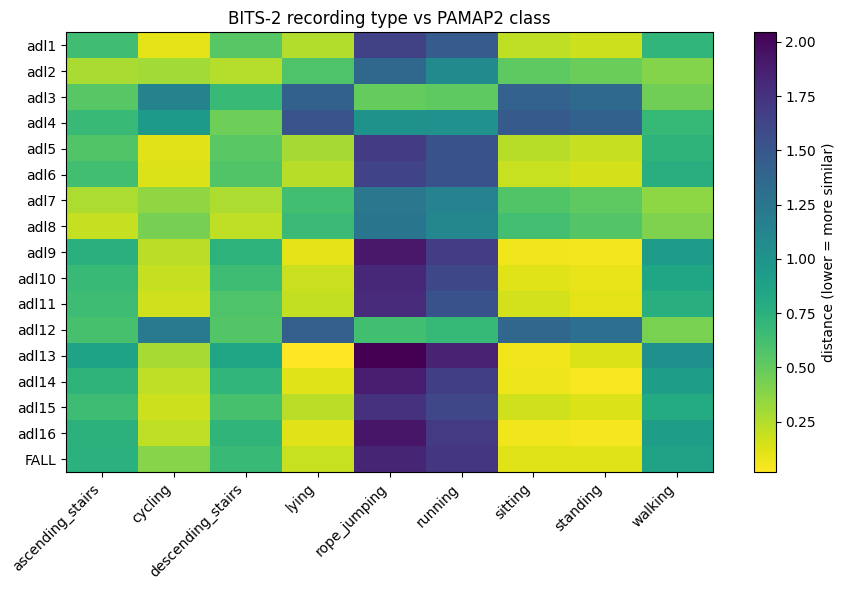

,adl,top_pred,share,2nd,users_agreeing,mean_conf
0,1,standing,0.69,cycling,0.85,0.49
1,2,ascending_stairs,0.33,walking,0.37,0.51
2,3,running,0.64,rope_jumping,0.78,0.61
3,4,running,0.34,rope_jumping,0.29,0.41
4,5,standing,0.46,cycling,0.73,0.48
5,6,standing,0.65,cycling,0.88,0.49
6,7,ascending_stairs,0.37,walking,0.45,0.47
7,8,ascending_stairs,0.33,descending_stairs,0.51,0.49
8,9,standing,0.50,sitting,0.71,0.50
9,10,standing,0.32,sitting,0.51,0.52


Evaluating on classes: ['ascending_stairs', 'descending_stairs', 'running', 'walking'] | windows: 9670 | users: 41


,model,accuracy,mean_confidence,ECE,log_loss
0,PAMAP2 only (calibrated),0.468,0.557,0.089,1.187
1,BITS-2 only,0.684,0.658,0.029,0.796
2,Joint training,0.669,0.642,0.031,0.810
3,Fusion w_pamap=0.25,0.672,0.625,0.047,0.813
4,Fusion w_pamap=0.5,0.638,0.594,0.046,0.876
5,Fusion w_pamap=0.75,0.560,0.578,0.018,0.992


thr=0.5: fall recall=0.994  ADL false-alarm rate=0.621  precision=0.444
thr=0.6: fall recall=0.985  ADL false-alarm rate=0.531  precision=0.480
thr=0.7: fall recall=0.969  ADL false-alarm rate=0.413  precision=0.539
thr=0.8: fall recall=0.849  ADL false-alarm rate=0.221  precision=0.657
thr=0.9: fall recall=0.634  ADL false-alarm rate=0.089  precision=0.780


In [63]:
# # Reinforcing PAMAP2 activity confidence with BITS-2 (wrist IMU) + fall detection
#
# Run this **after** your existing cells (it re-reads the raw files itself, so it only needs
# `/content/PAMAP2_Data/...` and `/content/BITS-2/Dataset/...` to exist).
#
# **What was wrong in the earlier cross-dataset experiment**
# 1. BITS-2 `acc` is centred on 0 (gravity already removed, i.e. the linear-acceleration channel). PAMAP2 accelerometer includes gravity. Use BITS-2 **`acg`** (+ `gyro`) to match PAMAP2.
# 2. Features such as `mean(|diff|)` depend on the sampling rate (100 Hz vs ~20 Hz or lower).
# 3. Per-axis means/mins/maxes depend on how the watch is oriented. Magnitudes and sorted per-axis std do not.
# 4. BITS-2 `t` is stored with 3 significant digits (e.g. `2.92E+12`), so it cannot be used to recover the sampling rate. Windows must be by sample count, with the rate estimated another way (Cell 2).
# 5. BITS-2 `adl1..adl16` are activities from the paper's Table 1, not class names. Do not treat them as classes to be matched blindly.


# %% [Cell 1]
# ===== Cell 1: config, loaders, harmonised features =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt, re
from pathlib import Path
from scipy.signal import resample_poly
from scipy.stats import wasserstein_distance
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, log_loss, classification_report

PAMAP_DIR = Path("/content/PAMAP2_Data/PAMAP2_Dataset/Protocol")
BITS_DIR  = Path("/content/BITS-2/Dataset")

N = 40            # samples per window (both datasets, after rate matching)
STRIDE = 20
RATE_HZ = 20      # PAMAP2 is decimated to this. Cell 2 estimates the real BITS-2 rate; update then re-run.

PAMAP_CLASSES = {1:"lying", 2:"sitting", 3:"standing", 4:"walking", 5:"running",
                 6:"cycling", 12:"ascending_stairs", 13:"descending_stairs", 24:"rope_jumping"}

FEATS = (["acc_mag_mean","acc_mag_std","acc_mag_min","acc_mag_max","acc_mag_p10","acc_mag_p90"]
       + ["gyr_mag_mean","gyr_mag_std","gyr_mag_max","gyr_mag_p10","gyr_mag_p90"]
       + ["acc_std_1","acc_std_2","acc_std_3","gyr_std_1","gyr_std_2","gyr_std_3"])

def window_features(acc, gyr):
    """acc, gyr: (N,3). Orientation- and rate-robust statistics only."""
    am = np.linalg.norm(acc, axis=1); gm = np.linalg.norm(gyr, axis=1)
    f = [am.mean(), am.std(), am.min(), am.max(), *np.percentile(am, [10, 90]),
         gm.mean(), gm.std(), gm.max(), *np.percentile(gm, [10, 90])]
    f += sorted(acc.std(axis=0), reverse=True)   # sorted -> independent of axis naming
    f += sorted(gyr.std(axis=0), reverse=True)
    return f

# ---------- PAMAP2 (dominant-hand IMU: acc16g cols 4-6, gyro cols 10-12) ----------
def load_pamap_runs():
    """Yield (subject, activity_id, imu[n,6] at native 100 Hz) for each contiguous labelled run."""
    for f in sorted(PAMAP_DIR.glob("subject*.dat")):
        subj = f.stem.replace("subject", "")
        df = pd.read_csv(f, sep=r"\s+", header=None, usecols=[1,4,5,6,10,11,12]).apply(pd.to_numeric, errors="coerce")
        act = df[1].fillna(0).astype(int).to_numpy()
        imu = df[[4,5,6,10,11,12]].interpolate(limit_direction="both").to_numpy(dtype=float)
        cuts = np.r_[0, np.flatnonzero(np.diff(act) != 0) + 1, len(act)]
        for s, e in zip(cuts[:-1], cuts[1:]):
            if act[s] in PAMAP_CLASSES and e - s >= 100:
                yield subj, int(act[s]), imu[s:e]

def build_pamap(rate_hz=RATE_HZ):
    rows = []
    for subj, a, run in load_pamap_runs():
        x = resample_poly(run, int(round(rate_hz)), 100, axis=0)   # anti-aliased decimation
        for i in range(0, len(x) - N + 1, STRIDE):
            w = x[i:i+N]
            rows.append(window_features(w[:, :3], w[:, 3:]) + [PAMAP_CLASSES[a], subj])
    return pd.DataFrame(rows, columns=FEATS + ["label", "subject"])

# ---------- BITS-2 (custom left-wrist device; streams: acc=linear, acg=with gravity, gyro, mgm) ----------
def read_bits_streams(path):
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    s = df["Unnamed: 5"].str.strip().str.lower()
    out = {}
    for name in ("acg", "gyro"):
        v = df.loc[s == name, ["x","y","z"]].apply(pd.to_numeric, errors="coerce").dropna().to_numpy(float)
        out[name] = v[np.isfinite(v).all(axis=1)]
    return out

def build_bits():
    rows = []
    for kind in ("adl", "fall"):
        for p in sorted((BITS_DIR / kind).rglob("*.csv")):
            st = read_bits_streams(p)
            n = min(len(st["acg"]), len(st["gyro"]))      # streams differ by 1-2 rows; align by index
            if n < N: continue
            a, g = st["acg"][:n], st["gyro"][:n]
            adl = int(re.search(r"_adl(\d+)", p.name).group(1)) if kind == "adl" else -1
            for i in range(0, n - N + 1, STRIDE):
                rows.append(window_features(a[i:i+N], g[i:i+N]) + [kind, adl, p.parent.name, p.name])
    return pd.DataFrame(rows, columns=FEATS + ["kind", "adl", "user", "file"])


# %% [Cell 2]
# ===== Cell 2: sanity checks BEFORE trusting any comparison =====
# (a) Effective BITS-2 sampling rate, estimated from walking cadence (timestamps are unusable).
def dom_cycles_per_sample(sig):
    x = (sig - sig.mean()) * np.hanning(len(sig))
    sp = np.abs(np.fft.rfft(x)); fr = np.fft.rfftfreq(len(sig))
    m = (fr > 0.004) & (fr < 0.5)
    return fr[m][sp[m].argmax()]

c_bits = []
for p in sorted((BITS_DIR / "adl").rglob("*_adl[12].csv")):         # adl1/adl2 = walking slowly / quickly (paper Table 1)
    a = read_bits_streams(p)["acg"]
    if len(a) > 128: c_bits.append(dom_cycles_per_sample(np.linalg.norm(a, axis=1)))
c_pam = [dom_cycles_per_sample(np.linalg.norm(r[:, :3], axis=1))
         for _, a, r in load_pamap_runs() if a == 4 and len(r) > 1000]
est = 100 * np.median(c_pam) / np.median(c_bits)
print(f"Walking cadence: PAMAP2 {np.median(c_pam):.4f} cyc/sample, BITS-2 {np.median(c_bits):.4f} cyc/sample")
print(f"=> estimated BITS-2 effective rate ≈ {est:.1f} Hz (paper says 20 Hz). Set RATE_HZ accordingly if they differ a lot.")

# (b) Build the feature tables
pam  = build_pamap(RATE_HZ)
bits = build_bits()
print("PAMAP2 windows:", pam.shape, "| BITS-2 windows:", bits.shape)

# (c) Gravity / unit check: the quietest windows should have |acc| ≈ 9.81 m/s²
for name, df in (("PAMAP2", pam), ("BITS-2 acg", bits)):
    q = df.nsmallest(max(20, len(df)//20), "acc_mag_std")
    print(f"{name}: quiet-window |acc| median = {q.acc_mag_mean.median():.2f}  (expect ~9.81; ~1.0 would mean units of g)")

# (d) Gyro unit check: PAMAP2 is rad/s. If BITS-2 walking were deg/s it would be ~57x larger.
print("Gyro |w| mean, median window: PAMAP2 walking = %.2f | BITS-2 adl1+adl2 = %.2f" % (
      pam.loc[pam.label=="walking","gyr_mag_mean"].median(),
      bits.loc[bits.adl.isin([1,2]),"gyr_mag_mean"].median()))


# %% [Cell 3]
# ===== Cell 3: your idea, done quantitatively — do the value ranges match per activity? =====
# Distance = median over features of Wasserstein distance, in units of pooled PAMAP2 IQR. Lower = more similar.
iqr = (pam[FEATS].quantile(.75) - pam[FEATS].quantile(.25)).replace(0, 1e-6).to_numpy()
def dist(A, B):
    return float(np.median([wasserstein_distance(A[:, j], B[:, j]) / iqr[j] for j in range(A.shape[1])]))

pam_cls = sorted(pam.label.unique())
rows = {}
groups = {f"adl{k}": bits[bits.adl == k] for k in sorted(bits.adl[bits.adl > 0].unique())}
groups["FALL"] = bits[bits.kind == "fall"]
for g, d in groups.items():
    rows[g] = [dist(d[FEATS].to_numpy(), pam.loc[pam.label == c, FEATS].to_numpy()) for c in pam_cls]
D = pd.DataFrame(rows, index=pam_cls).T
D["best_match"] = D[pam_cls].idxmin(axis=1)
D["margin"] = D[pam_cls].apply(lambda r: np.sort(r.values)[1] - np.sort(r.values)[0], axis=1)
display(D.round(2))

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(D[pam_cls].values, cmap="viridis_r", aspect="auto")
ax.set_xticks(range(len(pam_cls))); ax.set_xticklabels(pam_cls, rotation=45, ha="right")
ax.set_yticks(range(len(D))); ax.set_yticklabels(D.index)
plt.colorbar(im, label="distance (lower = more similar)"); plt.title("BITS-2 recording type vs PAMAP2 class"); plt.tight_layout(); plt.show()


# %% [Cell 4]
# ===== Cell 4: does a PAMAP2-trained model agree with what BITS-2 says each recording is? =====
pam_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
                                   random_state=42, n_jobs=-1).fit(pam[FEATS], pam.label)
adl = bits[bits.kind == "adl"].copy()
P = pam_model.predict_proba(adl[FEATS])
adl["pred"] = pam_model.classes_[P.argmax(1)]; adl["conf"] = P.max(1)

summary = []
for k, d in adl.groupby("adl"):
    top = d.pred.value_counts(normalize=True)
    per_user_top = d.groupby("user").pred.agg(lambda s: s.value_counts().index[0])
    summary.append({"adl": k, "top_pred": top.index[0], "share": round(top.iloc[0], 2),
                    "2nd": top.index[1] if len(top) > 1 else "-",
                    "users_agreeing": round((per_user_top == top.index[0]).mean(), 2),
                    "mean_conf": round(d.conf.mean(), 2)})
display(pd.DataFrame(summary))
# An adlN is a trustworthy cross-dataset match when: its meaning in Table 1 agrees with top_pred,
# share is high, users_agreeing is high, AND Cell 3 picks the same class.


# %% [Cell 5]
# ===== Cell 5: reinforce confidence — PAMAP2 knowledge + BITS-2 evidence, evaluated on UNSEEN BITS-2 users =====
# Mapping: ONLY use activities whose meaning is stated in the paper's Table 1 (Data in Brief 52:109812).
#   1 walking slowly, 2 walking quickly, 3 jogging, 5/7 climbing up, 6/8 climbing down, 9/10/11 sit-down transitions.
# adl4 and adl12-16 : open the paper's Table 1 and add them here if they match a PAMAP2 class.
# (jogging≈running and slow/fast walking≈walking are approximate matches — intensity differs, so treat as such.)
BITS_MAP = {1: "walking", 2: "walking", 3: "running",
            5: "ascending_stairs", 7: "ascending_stairs",
            6: "descending_stairs", 8: "descending_stairs"}

sub = bits[bits.adl.isin(BITS_MAP)].copy()
sub["label"] = sub.adl.map(BITS_MAP)
classes = sorted(sub.label.unique())
print("Evaluating on classes:", classes, "| windows:", len(sub), "| users:", sub.user.nunique())

# PAMAP2 model, probability-calibrated with subject-grouped CV (so calibration is not fit on seen subjects)
cv = list(GroupKFold(5).split(pam[FEATS], pam.label, pam.subject))
pam_cal = CalibratedClassifierCV(RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
          class_weight="balanced_subsample", random_state=42, n_jobs=-1), method="isotonic", cv=cv).fit(pam[FEATS].to_numpy(), pam.label.to_numpy())
col = [list(pam_cal.classes_).index(c) for c in classes]

def restrict(P):                       # keep only the shared classes, renormalise
    Q = P[:, col] + 1e-9
    return Q / Q.sum(1, keepdims=True)

def ece(P, y_idx, bins=10):
    conf, pred = P.max(1), P.argmax(1); e = 0.0
    edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs((pred[m] == y_idx[m]).mean() - conf[m].mean())
    return e

y = sub.label.map({c: i for i, c in enumerate(classes)}).to_numpy()
Xs = sub[FEATS].to_numpy()
Xs_all = sub[FEATS].to_numpy()
Pp = restrict(pam_cal.predict_proba(Xs_all))                 # PAMAP2 -> BITS-2 (zero BITS training data)
Pb = np.zeros_like(Pp); Pj = np.zeros_like(Pp)
Xpam = pam.loc[pam.label.isin(classes), FEATS].to_numpy(); ypam = pam.loc[pam.label.isin(classes), "label"].to_numpy()

for tr, te in GroupKFold(5).split(Xs, y, sub.user):
    rf = lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample", random_state=42, n_jobs=-1)
    mb = rf().fit(Xs[tr], sub.label.iloc[tr].to_numpy());  Pb[te] = mb.predict_proba(Xs[te])             # BITS-2 only
    mj = rf().fit(np.vstack([Xpam, Xs[tr]]), np.r_[ypam, sub.label.iloc[tr].to_numpy()])
    Pj[te] = mj.predict_proba(Xs[te])                                                           # joint training

def row(name, P):
    P = np.clip(P, 1e-6, 1); P = P / P.sum(1, keepdims=True)
    return {"model": name, "accuracy": accuracy_score(y, P.argmax(1)), "mean_confidence": P.max(1).mean(),
            "ECE": ece(P, y), "log_loss": log_loss(y, P, labels=range(len(classes)))}

res = [row("PAMAP2 only (calibrated)", Pp), row("BITS-2 only", Pb), row("Joint training", Pj)]
for a in (0.25, 0.5, 0.75):                                       # geometric fusion (product of experts)
    F = Pp**a * Pb**(1 - a); F /= F.sum(1, keepdims=True)
    res.append(row(f"Fusion  w_pamap={a}", F))
display(pd.DataFrame(res).round(3))
# Look for: fusion/joint with HIGHER accuracy and LOWER ECE/log-loss than either source alone.
# That (not just a higher "confidence" number) is what 'reinforced confidence' means.


# %% [Cell 6]
# ===== Cell 6: fall detection with the same harmonised features (event level) =====
bits["is_fall"] = (bits.kind == "fall").astype(int)
Xf, yf, gf = bits[FEATS].to_numpy(), bits.is_fall.to_numpy(), bits.user.to_numpy()
pf = np.zeros(len(bits))
for tr, te in GroupKFold(5).split(Xf, yf, gf):
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                               random_state=42, n_jobs=-1).fit(Xf[tr], yf[tr])
    pf[te] = m.predict_proba(Xf[te])[:, 1]
bits["p_fall"] = pf

# A recording is one event, so decide per recording: flag if the max window score exceeds a threshold.
rec = bits.groupby(["kind", "user", "file"]).p_fall.max().reset_index()
rec["y"] = (rec.kind == "fall").astype(int)
for thr in (0.5, 0.6, 0.7, 0.8, 0.9):
    pred = (rec.p_fall >= thr).astype(int)
    tp = ((pred == 1) & (rec.y == 1)).sum(); fn = ((pred == 0) & (rec.y == 1)).sum()
    fp = ((pred == 1) & (rec.y == 0)).sum(); tn = ((pred == 0) & (rec.y == 0)).sum()
    print(f"thr={thr}: fall recall={tp/(tp+fn):.3f}  ADL false-alarm rate={fp/(fp+tn):.3f}  precision={tp/max(tp+fp,1):.3f}")
# NOTE: ADL recordings are long (2 min) so they have many windows -> max-score rule inflates false alarms.
# If that dominates, require >=2 consecutive windows above the threshold, or add the PAMAP2 activity
# model as a gate (e.g. suppress a fall alarm when the model is highly confident of running/jumping).

In [ ]:
# # Activity recognition (PAMAP2 + MHEALTH) and fall detection (BITS-2)
# Run the cells **in order** (Cell 4 and 5 must come after Cell 3; Cell 6 is fall detection and is independent) in the same Colab session that already has `/content/PAMAP2_Data` and `/content/BITS-2`.
# MHEALTH is downloaded automatically in Cell 1 (if the download fails, upload the zip to `/content/` and re-run).

# %% [Cell 1]
# ===== Cell 1: setup, helpers, MHEALTH download =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt, re, zipfile, urllib.request
from pathlib import Path
from scipy.signal import resample_poly
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, log_loss, classification_report

PAMAP_DIR = Path("/content/PAMAP2_Data/PAMAP2_Dataset/Protocol")
BITS_DIR  = Path("/content/BITS-2/Dataset")
MH_ROOT   = Path("/content/MHEALTH")

# Activity recognition: both datasets at 50 Hz, 2-second windows
RATE_HZ, ACT_N, ACT_STRIDE = 50, 100, 50
# BITS-2 (fall detection): its true sampling rate is uncertain, so keep the 40-sample windows used before
BITS_N, BITS_STRIDE = 40, 20

PAMAP_CLASSES = {1:"lying", 2:"sitting", 3:"standing", 4:"walking", 5:"running",
                 6:"cycling", 12:"stairs", 13:"stairs", 24:"rope_jumping"}       # up/down stairs merged (MHEALTH has one stairs class)
MH_CLASSES = {1:"standing", 2:"sitting", 3:"lying", 4:"walking", 5:"stairs",
              9:"cycling", 10:"running", 11:"running"}

FEATS = (["acc_mag_mean","acc_mag_std","acc_mag_min","acc_mag_max","acc_mag_p10","acc_mag_p90"]
       + ["gyr_mag_mean","gyr_mag_std","gyr_mag_max","gyr_mag_p10","gyr_mag_p90"]
       + ["acc_std_1","acc_std_2","acc_std_3","gyr_std_1","gyr_std_2","gyr_std_3"])

def window_features(acc, gyr):
    """acc, gyr: (n,3). Orientation-robust statistics (magnitudes + sorted per-axis std)."""
    am = np.linalg.norm(acc, axis=1); gm = np.linalg.norm(gyr, axis=1)
    f = [am.mean(), am.std(), am.min(), am.max(), *np.percentile(am, [10, 90]),
         gm.mean(), gm.std(), gm.max(), *np.percentile(gm, [10, 90])]
    f += sorted(acc.std(axis=0), reverse=True)
    f += sorted(gyr.std(axis=0), reverse=True)
    return f

def windows_from_run(x, label, subj, n=ACT_N, stride=ACT_STRIDE):
    return [window_features(x[i:i+n, :3], x[i:i+n, 3:]) + [label, subj] for i in range(0, len(x) - n + 1, stride)]

def runs(labels):
    cuts = np.r_[0, np.flatnonzero(np.diff(labels) != 0) + 1, len(labels)]
    return zip(cuts[:-1], cuts[1:])

# ---------- PAMAP2: dominant-hand IMU, acc16g cols 4-6 (m/s², with gravity), gyro cols 10-12 (rad/s), 100 Hz ----------
def build_pamap(rate_hz=RATE_HZ):
    rows = []
    for f in sorted(PAMAP_DIR.glob("subject*.dat")):
        subj = "P" + f.stem.replace("subject", "")
        df = pd.read_csv(f, sep=r"\s+", header=None, usecols=[1,4,5,6,10,11,12]).apply(pd.to_numeric, errors="coerce")
        act = df[1].fillna(0).astype(int).to_numpy()
        imu = df[[4,5,6,10,11,12]].interpolate(limit_direction="both").to_numpy(float)
        for s, e in runs(act):
            if act[s] in PAMAP_CLASSES and e - s >= 100:
                x = resample_poly(imu[s:e], rate_hz, 100, axis=0)
                rows += windows_from_run(x, PAMAP_CLASSES[act[s]], subj)
    return pd.DataFrame(rows, columns=FEATS + ["label", "subject"])

# ---------- MHEALTH: right lower arm, acc cols 15-17 (m/s², gravity), gyro cols 18-20 (deg/s!), 50 Hz, label col 24 ----------
def get_mhealth():
    if list(MH_ROOT.rglob("mHealth_subject*.log")): return
    MH_ROOT.mkdir(exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/319/mhealth+dataset.zip"
    urllib.request.urlretrieve(url, MH_ROOT / "outer.zip")
    zipfile.ZipFile(MH_ROOT / "outer.zip").extractall(MH_ROOT)
    for z in list(MH_ROOT.rglob("*.zip")):
        if z.name != "outer.zip": zipfile.ZipFile(z).extractall(MH_ROOT)
    print("MHEALTH files:", len(list(MH_ROOT.rglob("mHealth_subject*.log"))))

def build_mhealth():
    get_mhealth(); rows = []
    for f in sorted(MH_ROOT.rglob("mHealth_subject*.log")):
        subj = "M" + re.search(r"subject(\d+)", f.name).group(1)
        d = np.loadtxt(f); lab = d[:, 23].astype(int)
        imu = d[:, [14,15,16,17,18,19]].copy(); imu[:, 3:] *= np.pi / 180      # deg/s -> rad/s
        for s, e in runs(lab):
            if lab[s] in MH_CLASSES and e - s >= 100:
                rows += windows_from_run(imu[s:e], MH_CLASSES[lab[s]], subj)
    return pd.DataFrame(rows, columns=FEATS + ["label", "subject"])

# ---------- BITS-2: use acg (with gravity) + gyro ----------
def read_bits_streams(path):
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    s = df["Unnamed: 5"].str.strip().str.lower(); out = {}
    for name in ("acg", "gyro"):
        v = df.loc[s == name, ["x","y","z"]].apply(pd.to_numeric, errors="coerce").dropna().to_numpy(float)
        out[name] = v[np.isfinite(v).all(axis=1)]
    return out

def build_bits(n=BITS_N, stride=BITS_STRIDE):
    rows = []
    for kind in ("adl", "fall"):
        for p in sorted((BITS_DIR / kind).rglob("*.csv")):
            st = read_bits_streams(p); m = min(len(st["acg"]), len(st["gyro"]))
            if m < n: continue
            a, g = st["acg"][:m], st["gyro"][:m]
            adl = int(re.search(r"_adl(\d+)", p.name).group(1)) if kind == "adl" else -1
            for k, i in enumerate(range(0, m - n + 1, stride)):
                rows.append(window_features(a[i:i+n], g[i:i+n]) + [kind, adl, p.parent.name, p.name, k])
    return pd.DataFrame(rows, columns=FEATS + ["kind", "adl", "user", "file", "win"])

# %% [Cell 2]
# ===== Cell 2: build tables + sanity checks =====
pam = build_pamap()
mh  = build_mhealth()
print("PAMAP2 windows:", pam.shape, "| MHEALTH windows:", mh.shape)
print("\nWindows per class:\n", pd.concat({"PAMAP2": pam.label.value_counts(), "MHEALTH": mh.label.value_counts()}, axis=1))

for name, df in (("PAMAP2", pam), ("MHEALTH", mh)):
    q = df.nsmallest(max(20, len(df)//20), "acc_mag_std")
    print(f"{name}: quiet |acc| = {q.acc_mag_mean.median():.2f} (expect ~9.81)")
print("\nGyro magnitude (median window), per shared class: PAMAP2 vs MHEALTH")
print(pd.concat({"PAMAP2": pam.groupby("label").gyr_mag_mean.median(),
                 "MHEALTH": mh.groupby("label").gyr_mag_mean.median()}, axis=1).round(2))
# Ratios near 1-3 are fine. A ratio near 57 would mean a deg/s vs rad/s mix-up.

# %% [Cell 3]
# ===== Cell 3: does MHEALTH reinforce PAMAP2? (evaluated on UNSEEN MHEALTH subjects) =====
shared = sorted(set(pam.label) & set(mh.label)); print("Shared classes:", shared)
pam_s = pam[pam.label.isin(shared)]
mh = mh[mh.label.isin(shared)].reset_index(drop=True)
ci = {c: i for i, c in enumerate(shared)}
y  = mh.label.map(ci).to_numpy(); Xm = mh[FEATS].to_numpy(); gm_ = mh.subject.to_numpy()
Xp = pam_s[FEATS].to_numpy(); yp = pam_s.label.to_numpy()
RF = lambda: RandomForestClassifier(n_estimators=250, min_samples_leaf=2, class_weight="balanced_subsample", random_state=42, n_jobs=-1)

# Reference: PAMAP2 in-domain (leave-subjects-out) on the shared classes
pin = np.empty(len(pam_s), dtype=object)
for tr, te in GroupKFold(5).split(Xp, yp, pam_s.subject):
    pin[te] = RF().fit(Xp[tr], yp[tr]).predict(Xp[te])
print(f"PAMAP2 in-domain accuracy (unseen PAMAP2 subjects): {accuracy_score(yp, pin):.3f}")

# PAMAP2 model, calibrated with subject-grouped CV, applied to MHEALTH with NO MHEALTH training data
pam_all = pam.copy()
cv = list(GroupKFold(5).split(pam_all[FEATS], pam_all.label, pam_all.subject))
cal = CalibratedClassifierCV(RF(), method="isotonic", cv=cv).fit(pam_all[FEATS].to_numpy(), pam_all.label.to_numpy())
col = [list(cal.classes_).index(c) for c in shared]
Pp = cal.predict_proba(Xm)[:, col] + 1e-9; Pp /= Pp.sum(1, keepdims=True)
print(f"\nPAMAP2 -> MHEALTH (zero MHEALTH training): accuracy {accuracy_score(y, Pp.argmax(1)):.3f}")
print(classification_report(y, Pp.argmax(1), target_names=shared, zero_division=0))

def ece(P, yi, bins=10):
    conf, pred = P.max(1), P.argmax(1); e = 0.0; edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs((pred[m] == yi[m]).mean() - conf[m].mean())
    return e
def row(name, P):
    P = np.clip(P, 1e-6, 1); P = P / P.sum(1, keepdims=True)
    return {"model": name, "accuracy": accuracy_score(y, P.argmax(1)), "mean_conf": P.max(1).mean(),
            "ECE": ece(P, y), "log_loss": log_loss(y, P, labels=range(len(shared)))}

Pb = np.zeros_like(Pp); Pj = np.zeros_like(Pp)
for tr, te in GroupKFold(5).split(Xm, y, gm_):
    Pb[te] = RF().fit(Xm[tr], mh.label.iloc[tr].to_numpy()).predict_proba(Xm[te])
    Pj[te] = RF().fit(np.vstack([Xp, Xm[tr]]), np.r_[yp, mh.label.iloc[tr].to_numpy()]).predict_proba(Xm[te])
res = [row("PAMAP2 only (calibrated)", Pp), row("MHEALTH only", Pb), row("Joint training", Pj)]
for a in (0.25, 0.5, 0.75):
    F = Pp**a * Pb**(1 - a); res.append(row(f"Fusion w_pamap={a}", F))
display(pd.DataFrame(res).round(3))
print("Reinforcement is real only if Joint/Fusion beat BOTH single-source rows on accuracy AND ECE/log_loss.")

# %% [Cell 4]
# ===== Cell 4: diagnostic: which MHEALTH columns actually carry motion? =====
d = np.loadtxt(next(MH_ROOT.rglob("mHealth_subject1.log")))
lab = d[:, 23].astype(int)
tab = pd.DataFrame({f"col{c+1}": [d[lab == a, c].std() for a in (1, 4, 11)] for c in range(14, 23)},
                   index=["standing", "walking", "running"])
print("Std of raw right-lower-arm columns (15-17 acc, 18-20 gyro, 21-23 mag):")
print(tab.round(2))

# %% [Cell 5]
# ===== Cell 5: accelerometer-only transfer PAMAP2 -> MHEALTH (ignores the suspicious gyro) =====
AF = [f for f in FEATS if f.startswith("acc")]
cal2 = CalibratedClassifierCV(RF(), method="isotonic", cv=cv).fit(pam_all[AF].to_numpy(), pam_all.label.to_numpy())
P2 = cal2.predict_proba(mh[AF].to_numpy())[:, col] + 1e-9; P2 /= P2.sum(1, keepdims=True)
print("\nAcc-only PAMAP2 -> MHEALTH accuracy:", round(accuracy_score(y, P2.argmax(1)), 3))
print(classification_report(y, P2.argmax(1), target_names=shared, zero_division=0))

Pb2 = np.zeros_like(P2); Pj2 = np.zeros_like(P2)
for tr, te in GroupKFold(5).split(mh[AF].to_numpy(), y, gm_):
    Xa = mh[AF].to_numpy()
    Pb2[te] = RF().fit(Xa[tr], mh.label.iloc[tr].to_numpy()).predict_proba(Xa[te])
    Pj2[te] = RF().fit(np.vstack([pam_s[AF].to_numpy(), Xa[tr]]), np.r_[yp, mh.label.iloc[tr].to_numpy()]).predict_proba(Xa[te])
res2 = [row("PAMAP2 only (acc)", P2), row("MHEALTH only (acc)", Pb2), row("Joint (acc)", Pj2)]
for a in (0.25, 0.5):
    res2.append(row(f"Fusion w_pamap={a} (acc)", P2**a * Pb2**(1 - a)))
display(pd.DataFrame(res2).round(3))

# %% [Cell 6]
# ===== Cell 6: fall detection with impact-centred labels =====
# Problem in the first version: every window of a fall recording was labelled "fall", including the quiet
# seconds before/after the impact. Now only windows containing the acceleration peak are positives, other
# windows of fall recordings are left out of training, and the decision is still made per recording.
def build_bits_v2(n=BITS_N, stride=BITS_STRIDE):
    rows = []
    for kind in ("adl", "fall"):
        for p in sorted((BITS_DIR / kind).rglob("*.csv")):
            st = read_bits_streams(p); m = min(len(st["acg"]), len(st["gyro"]))
            if m < n: continue
            a, g = st["acg"][:m], st["gyro"][:m]
            peak = int(np.argmax(np.linalg.norm(a, axis=1))) if kind == "fall" else -1
            for k, i in enumerate(range(0, m - n + 1, stride)):
                impact = int(kind == "fall" and i <= peak < i + n)
                rows.append(window_features(a[i:i+n], g[i:i+n]) + [kind, p.parent.name, p.name, k, impact])
    return pd.DataFrame(rows, columns=FEATS + ["kind", "user", "file", "win", "impact"])

bits = build_bits_v2()
train_ok = ((bits.kind == "adl") | (bits.impact == 1)).to_numpy()
Xf, yf, gf = bits[FEATS].to_numpy(), bits.impact.to_numpy(), bits.user.to_numpy()
pf = np.zeros(len(bits))
for tr, te in GroupKFold(5).split(Xf, yf, gf):
    tr = tr[train_ok[tr]]
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                               random_state=42, n_jobs=-1).fit(Xf[tr], yf[tr])
    pf[te] = m.predict_proba(Xf[te])[:, 1]
bits["p_fall"] = pf

recs = []
for (kind, user, file), g in bits.groupby(["kind", "user", "file"]):
    p = g.sort_values("win").p_fall.to_numpy()
    recs.append((kind, p.max(), np.minimum(p[:-1], p[1:]).max() if len(p) > 1 else p.max()))
rec = pd.DataFrame(recs, columns=["kind", "max1", "max2"]); rec["y"] = (rec.kind == "fall").astype(int)
out = []
for rule in ("max1", "max2"):
    for thr in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
        pred = (rec[rule] >= thr).astype(int); yy = rec.y
        tp = ((pred == 1) & (yy == 1)).sum(); fn = ((pred == 0) & (yy == 1)).sum()
        fp = ((pred == 1) & (yy == 0)).sum(); tn = ((pred == 0) & (yy == 0)).sum()
        out.append({"rule": rule, "thr": thr, "fall_recall": tp/(tp+fn), "ADL_false_alarm": fp/(fp+tn), "precision": tp/max(tp+fp, 1)})
display(pd.DataFrame(out).round(3))

PAMAP2 windows: (13285, 19) | MHEALTH windows: (4792, 19)

Windows per class:
               PAMAP2  MHEALTH
label                        
walking         2377    600.0
stairs          2174    592.0
lying           1914    600.0
standing        1888    600.0
sitting         1839    600.0
cycling         1635    600.0
running          973   1200.0
rope_jumping     485      NaN
PAMAP2: quiet |acc| = 9.74 (expect ~9.81)
MHEALTH: quiet |acc| = 9.73 (expect ~9.81)

Gyro magnitude (median window), per shared class: PAMAP2 vs MHEALTH
              PAMAP2  MHEALTH
label                        
cycling         0.70     0.02
lying           0.03     0.02
rope_jumping    4.31      NaN
running         4.02     0.02
sitting         0.05     0.02
stairs          1.91     0.02
standing        0.13     0.02
walking         2.64     0.02
Shared classes: ['cycling', 'lying', 'running', 'sitting', 'stairs', 'standing', 'walking']
PAMAP2 in-domain accuracy (unseen PAMAP2 subjects): 0.648

PAMAP2 -> MHEALT

,model,accuracy,mean_conf,ECE,log_loss
0,PAMAP2 only (calibrated),0.261,0.601,0.340,2.658
1,MHEALTH only,0.749,0.880,0.141,1.006
2,Joint training,0.746,0.866,0.142,0.912
3,Fusion w_pamap=0.25,0.746,0.844,0.105,0.972
4,Fusion w_pamap=0.5,0.696,0.811,0.115,1.083
5,Fusion w_pamap=0.75,0.577,0.801,0.224,1.387


Reinforcement is real only if Joint/Fusion beat BOTH single-source rows on accuracy AND ECE/log_loss.
Std of raw right-lower-arm columns (15-17 acc, 18-20 gyro, 21-23 mag):
          col15  col16  col17  col18  col19  col20  col21  col22   col23
standing   0.14   0.11   0.11   0.01   0.01   0.01   0.35   0.69    0.70
walking    1.38   2.34   0.87   0.08   0.08   0.07   6.73  25.61   41.42
running   10.52  11.37   5.71   0.22   0.22   0.23  87.20  65.12  219.28

Acc-only PAMAP2 -> MHEALTH accuracy: 0.482
              precision    recall  f1-score   support

     cycling       0.64      0.80      0.71       600
       lying       0.31      0.17      0.22       600
     running       1.00      0.62      0.76      1200
     sitting       0.29      0.46      0.36       600
      stairs       0.28      0.48      0.36       592
    standing       0.32      0.35      0.34       600
     walking       0.59      0.37      0.45       600

    accuracy                           0.48      4792
   

,model,accuracy,mean_conf,ECE,log_loss
0,PAMAP2 only (acc),0.482,0.516,0.049,1.144
1,MHEALTH only (acc),0.730,0.779,0.050,0.596
2,Joint (acc),0.723,0.720,0.011,0.630
3,Fusion w_pamap=0.25 (acc),0.738,0.749,0.023,0.569
4,Fusion w_pamap=0.5 (acc),0.729,0.717,0.020,0.574


,rule,thr,fall_recall,ADL_false_alarm,precision
0,max1,0.3,0.883,0.130,0.772
1,max1,0.4,0.846,0.101,0.806
2,max1,0.5,0.763,0.071,0.844
3,max1,0.6,0.714,0.040,0.899
4,max1,0.7,0.606,0.021,0.934
5,max1,0.8,0.498,0.011,0.959
6,max1,0.9,0.385,0.002,0.992
7,max2,0.3,0.760,0.071,0.843
8,max2,0.4,0.689,0.043,0.889
9,max2,0.5,0.628,0.026,0.923


In [ ]:
"""Live test on your laptop. The board must print one line per sample over USB-serial:   ax,ay,az,gx,gy,gz
Examples:
   python live_inference.py --port COM5 --fs 100 --log session1.csv        (live from board)
   python live_inference.py --file session1.csv --fs 100                   (replay a saved log)
Dependencies: pip install pyserial numpy scipy scikit-learn==<version printed by training> joblib pandas"""
import argparse, collections, sys, time, numpy as np, joblib
from scipy.signal import resample_poly
from har_common import window_features

G = 9.80665
ap = argparse.ArgumentParser()
ap.add_argument("--bundle", default="har_bundle.joblib")
ap.add_argument("--port"); ap.add_argument("--baud", type=int, default=115200)
ap.add_argument("--file"); ap.add_argument("--log")
ap.add_argument("--fs", type=int, default=100, help="IMU sample rate printed by the board (Hz)")
ap.add_argument("--acc_unit", choices=["g", "ms2"], default="g")
ap.add_argument("--gyro_unit", choices=["dps", "rads"], default="dps")
a = ap.parse_args()

B = joblib.load(a.bundle)
acc_k  = G if a.acc_unit == "g" else 1.0
gyro_k = np.pi / 180 if a.gyro_unit == "dps" else 1.0
buf = collections.deque(maxlen=2 * a.fs); hop = a.fs // 2; n_in = 0; mags = []

def predict(w):
    w = np.asarray(w, float).copy(); w[:, :3] *= acc_k; w[:, 3:] *= gyro_k
    act = resample_poly(w, B["act_rate"], a.fs, axis=0)[: B["act_n"]]
    fal = resample_poly(w, B["fall_rate"], a.fs, axis=0)[: B["fall_n"]]
    p = B["act_model"].predict_proba([window_features(act[:, :3], act[:, 3:])])[0]
    k = int(p.argmax()); label = B["act_classes"][k] if p[k] >= B["abstain_thr"] else "uncertain"
    pf = B["fall_model"].predict_proba([window_features(fal[:, :3], fal[:, 3:])])[0, 1]
    return label, p[k], pf, float(np.linalg.norm(w[:, :3], axis=1).mean())

def handle(vals):
    global n_in
    buf.append(vals); n_in += 1
    if len(buf) == buf.maxlen and n_in % hop == 0:
        label, conf, pf, mag = predict(list(buf)); mags.append(mag)
        flag = "  <<< FALL?" if pf >= B["fall_thr"] else ""
        print(f"t={n_in/a.fs:7.1f}s  activity={label:10s} conf={conf:.2f}  p_fall={pf:.2f}  |acc|={mag:5.2f}{flag}", flush=True)
        if len(mags) == 10 and not (6.0 < np.median(mags) < 14.0):
            print("!! WARNING: mean |acc| is far from 9.81 m/s^2 -> check --acc_unit / sensor range / axis order", flush=True)

def lines():
    if a.file:
        yield from open(a.file)
    else:
        import serial
        s = serial.Serial(a.port, a.baud, timeout=1)
        while True:
            yield s.readline().decode(errors="ignore")

log = open(a.log, "w") if a.log else None
if log: log.write("ax,ay,az,gx,gy,gz\n")
try:
    for line in lines():
        parts = line.strip().split(",")
        if len(parts) != 6: continue
        try: vals = [float(x) for x in parts]
        except ValueError: continue
        if log: log.write(line.strip() + "\n")
        handle(vals)
except KeyboardInterrupt:
    pass
finally:
    if log: log.close()

In [65]:
"""Train small neural nets on the SAME 17 window features and export them as INT8 TensorFlow Lite models.
Run in Colab after uploading har_common.py:   !python /content/export_tflite_int8.py
Outputs (in /content, or current folder):
   activity_int8.tflite, fall_int8.tflite   - the models
   activity_int8.cc,     fall_int8.cc       - same models as C arrays for firmware
   export_params.json                       - feature mean/std, class names, input/output quantisation, thresholds
The firmware must (1) compute the same 17 features, (2) standardise them with mean/std, (3) quantise with the input
scale/zero-point, (4) run the model, (5) dequantise the output. Verify against the Python numbers printed here."""
import os, sys, json, io, contextlib, warnings
warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
sys.path.insert(0, "/content"); sys.path.insert(0, ".")
import numpy as np, pandas as pd, tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
import har_common as hc
tf.keras.utils.set_random_seed(42)
OUT = "/content" if os.path.isdir("/content") else "."

def mlp(n_in, n_out, h1, h2):
    return tf.keras.Sequential([tf.keras.layers.Input((n_in,)),
        tf.keras.layers.Dense(h1, activation="relu"), tf.keras.layers.Dense(h2, activation="relu"),
        tf.keras.layers.Dense(n_out, activation="softmax")])

def fit(X, y, n_out, h1, h2, weights=None, epochs=80, early_stop=True):
    m = mlp(X.shape[1], n_out, h1, h2)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    if early_stop:      # fine for the activity model (balanced-ish classes)
        m.fit(X, y, epochs=epochs, batch_size=128, validation_split=0.15, class_weight=weights, verbose=0,
              callbacks=[tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    else:               # fall model: validation loss is UNweighted and would pick an "always no-fall" model
        m.fit(X, y, epochs=epochs, batch_size=128, class_weight=weights, verbose=0)
    return m

def to_int8(model, X_rep):
    conv = tf.lite.TFLiteConverter.from_keras_model(model)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    rep = X_rep[np.random.default_rng(0).choice(len(X_rep), min(500, len(X_rep)), replace=False)].astype(np.float32)
    conv.representative_dataset = lambda: ([r[None, :]] for r in rep)
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = tf.int8; conv.inference_output_type = tf.int8
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        return conv.convert()

def run_int8(tfl, X):
    it = tf.lite.Interpreter(model_content=tfl); it.allocate_tensors()
    i, o = it.get_input_details()[0], it.get_output_details()[0]
    (s_i, z_i), (s_o, z_o) = i["quantization"], o["quantization"]
    P = np.zeros((len(X), o["shape"][1]), np.float32)
    for k, x in enumerate(X):
        q = np.clip(np.round(x / s_i + z_i), -128, 127).astype(np.int8)[None, :]
        it.set_tensor(i["index"], q); it.invoke()
        P[k] = (it.get_tensor(o["index"])[0].astype(np.float32) - z_o) * s_o
    return P, {"in_scale": float(s_i), "in_zero_point": int(z_i), "out_scale": float(s_o), "out_zero_point": int(z_o)}

def c_array(tfl, name, path):
    with open(path, "w") as f:
        f.write(f"// {name}: INT8 TFLite model, {len(tfl)} bytes\nalignas(16) const unsigned char {name}[] = {{\n")
        for k in range(0, len(tfl), 12): f.write("  " + ", ".join(f"0x{b:02x}" for b in tfl[k:k+12]) + ",\n")
        f.write(f"}};\nconst unsigned int {name}_len = {len(tfl)};\n")

MODELS = {}

def pipeline(name, X, y, g, classes, h1, h2, weights=None, epochs=80, early_stop=True):
    mean, std = X.mean(0), X.std(0) + 1e-6
    Z = ((X - mean) / std).astype(np.float32)
    # honest check: hold out whole subjects/users, compare float vs INT8
    tr, te = next(GroupShuffleSplit(1, test_size=0.25, random_state=1).split(Z, y, g))
    m_eval = fit(Z[tr], y[tr], len(classes), h1, h2, weights, epochs, early_stop)
    Pf = m_eval.predict(Z[te], verbose=0)
    Pq, _ = run_int8(to_int8(m_eval, Z[tr]), Z[te])
    print(f"\n[{name}] held-out accuracy  float: {(Pf.argmax(1)==y[te]).mean():.3f} | INT8: {(Pq.argmax(1)==y[te]).mean():.3f} "
          f"| float/INT8 agreement: {(Pf.argmax(1)==Pq.argmax(1)).mean():.3f}")
    print(f"[{name}] mean confidence float {Pf.max(1).mean():.3f} vs INT8 {Pq.max(1).mean():.3f}  (INT8 confidences must be re-checked)")
    # final model on all data -> export
    m = fit(Z, y, len(classes), h1, h2, weights, epochs, early_stop)
    tfl = to_int8(m, Z); MODELS[name] = tfl
    _, q = run_int8(tfl, Z[:5])
    open(f"{OUT}/{name}_int8.tflite", "wb").write(tfl); c_array(tfl, f"{name}_model", f"{OUT}/{name}_int8.cc")
    print(f"[{name}] saved {OUT}/{name}_int8.tflite  ({len(tfl)/1024:.1f} KB)")
    return {"classes": classes, "mean": mean.tolist(), "std": std.tolist(), **q}, Pq, y[te], Pf

params = {"feats": hc.FEATS, "act_rate_hz": hc.ACT_RATE, "act_window": hc.ACT_N,
          "fall_rate_hz": hc.FALL_RATE, "fall_window": hc.FALL_N}

# ---- activity (PAMAP2) ----
pam = hc.build_pamap_activity()
classes = sorted(pam.label.unique()); cmap = {c: i for i, c in enumerate(classes)}
ya = pam.label.map(cmap).to_numpy()
cw = {i: len(ya) / (len(classes) * (ya == i).sum()) for i in range(len(classes))}
params["activity"], Pq, yt, _ = pipeline("activity", pam[hc.FEATS].to_numpy(), ya, pam.subject.to_numpy(), classes, 32, 16, cw)
print("INT8 abstain table on held-out subjects (conf >= thr -> accept):")
ACT_TARGET_ACC, abst = 0.94, None
for thr in (0.5, 0.6, 0.7, 0.8, 0.9):
    k = Pq.max(1) >= thr
    acc = (Pq[k].argmax(1) == yt[k]).mean() if k.any() else float("nan")
    print(f"  thr={thr}: coverage={k.mean():.2f} accuracy_on_accepted={acc:.3f}")
    if abst is None and acc >= ACT_TARGET_ACC: abst = thr
params["activity"]["abstain_thr"] = abst if abst is not None else 0.8
print("Chosen activity abstain threshold:", params["activity"]["abstain_thr"])

# ---- fall (BITS-2, impact-centred) ----
bits = hc.build_bits_falls()
ok = ((bits.kind == "adl") | (bits.impact == 1)).to_numpy(); b = bits[ok]
yf = b.impact.to_numpy()
wf = {0: 1.0, 1: float(min((yf == 0).sum() / max((yf == 1).sum(), 1), 30))}
params["fall"], Pq, yt, Pf = pipeline("fall", b[hc.FEATS].to_numpy(), yf, b.user.to_numpy(), ["no_fall", "fall"], 24, 12, wf,
                                      epochs=120, early_stop=False)

# Cross-validated INT8 probabilities for EVERY window of unseen users, then decisions PER RECORDING.
print("\nCross-validating the INT8 fall model over users (5 folds)...")
Xall, yall, gall = bits[hc.FEATS].to_numpy(), bits.impact.to_numpy(), bits.user.to_numpy()
pcv = np.zeros(len(bits))
for f, (tr, te) in enumerate(GroupKFold(5).split(Xall, yall, gall)):
    tr = tr[ok[tr]]; mu, sd = Xall[tr].mean(0), Xall[tr].std(0) + 1e-6
    Ztr = ((Xall[tr] - mu) / sd).astype(np.float32)
    w_ = {0: 1.0, 1: float(min((yall[tr] == 0).sum() / max((yall[tr] == 1).sum(), 1), 30))}
    mf = fit(Ztr, yall[tr], 2, 24, 12, w_, epochs=120, early_stop=False)
    P_, _ = run_int8(to_int8(mf, Ztr), ((Xall[te] - mu) / sd).astype(np.float32)); pcv[te] = P_[:, 1]
    print(f"  fold {f+1}/5 done")
bits["p"] = pcv

recs = {}
win, astd = bits.win.to_numpy(), bits.acc_mag_std.to_numpy()
for key, idx in bits.groupby(["kind", "user", "file"]).indices.items():
    o = idx[np.argsort(win[idx])]; recs[key] = (pcv[o], astd[o])

def alarm(p, a, thr, still):
    for k in np.flatnonzero(p >= thr):
        if still is None: return True
        post = [j for j in (k + 2, k + 3) if j < len(p)]          # windows fully AFTER the impact window
        if not post or min(a[j] for j in post) < still: return True
    return False

rows = []
for thr in (0.5, 0.7, 0.8, 0.9, 0.95):
    for still in (None, 0.5, 1.0, 2.0, 3.0):
        fa = [alarm(p, a, thr, still) for (kd, _, _), (p, a) in recs.items() if kd == "adl"]
        fl = [alarm(p, a, thr, still) for (kd, _, _), (p, a) in recs.items() if kd == "fall"]
        rows.append({"thr": thr, "still_std": still, "fall_recall": np.mean(fl), "ADL_false_alarm": np.mean(fa)})
R = pd.DataFrame(rows)
print("\nPER-RECORDING results of the INT8 fall model on unseen users (still_std: next-window motion must be below this, m/s^2):")
print(R.round(3).to_string(index=False))
good = R[R.fall_recall >= 0.80]
best = (good.sort_values(["ADL_false_alarm", "fall_recall"], ascending=[True, False]).iloc[0] if len(good)
        else R.sort_values("fall_recall", ascending=False).iloc[0])
params["fall"]["threshold"] = float(best.thr)
params["fall"]["still_std"] = None if pd.isna(best.still_std) else float(best.still_std)
print(f"\nChosen fall rule: thr={best.thr}, still_std={params['fall']['still_std']} "
      f"-> recall {best.fall_recall:.2f}, ADL false alarm {best.ADL_false_alarm:.2f} (per recording)")

# ---- golden test vectors for the firmware ----
def golden(name, wins, key):
    P = params[name]; mean, std = np.array(P["mean"]), np.array(P["std"]); out = []
    for gw in wins:
        w = np.array(gw["window"]); f = np.array(hc.window_features(w[:, :3], w[:, 3:])); z = ((f - mean) / std).astype(np.float32)
        probs, _ = run_int8(MODELS[name], z[None, :])
        q_in = np.clip(np.round(z / P["in_scale"] + P["in_zero_point"]), -128, 127).astype(int)
        out.append({key: gw[key], "raw_window_rowmajor": w.round(5).ravel().tolist(), "features": f.round(6).tolist(),
                    "int8_input": q_in.tolist(), "probs_int8_model": probs[0].round(5).tolist()})
    return out
G = hc.golden_raw_windows()
json.dump({"note": "raw windows are rows of [ax,ay,az (m/s^2), gx,gy,gz (rad/s)]; activity window=%d rows @%d Hz, fall window=%d rows @%d Hz"
           % (hc.ACT_N, hc.ACT_RATE, hc.FALL_N, hc.FALL_RATE),
           "activity": golden("activity", G["activity"], "label"), "fall": golden("fall", G["fall"], "kind")},
          open(f"{OUT}/golden_vectors.json", "w"))
print("Saved", f"{OUT}/golden_vectors.json  (use it to check the C feature code + model on the chip)")

json.dump(params, open(f"{OUT}/export_params.json", "w"), indent=1)
print("\nSaved", f"{OUT}/export_params.json")


[activity] held-out accuracy  float: 0.900 | INT8: 0.899 | float/INT8 agreement: 0.988
[activity] mean confidence float 0.897 vs INT8 0.896  (INT8 confidences must be re-checked)
[activity] saved /content/activity_int8.tflite  (5.1 KB)
INT8 abstain table on held-out subjects (conf >= thr -> accept):
  thr=0.5: coverage=0.96 accuracy_on_accepted=0.915
  thr=0.6: coverage=0.93 accuracy_on_accepted=0.926
  thr=0.7: coverage=0.88 accuracy_on_accepted=0.943
  thr=0.8: coverage=0.83 accuracy_on_accepted=0.958
  thr=0.9: coverage=0.74 accuracy_on_accepted=0.971
Chosen activity abstain threshold: 0.7

[fall] held-out accuracy  float: 0.968 | INT8: 0.969 | float/INT8 agreement: 0.998
[fall] mean confidence float 0.948 vs INT8 0.947  (INT8 confidences must be re-checked)
[fall] saved /content/fall_int8.tflite  (4.3 KB)

Cross-validating the INT8 fall model over users (5 folds)...
  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done
  fold 5/5 done

PER-RECORDING results of the INT8 f

In [66]:
import importlib, sys, json, os
sys.path.insert(0, "/content")
print(os.popen("ls -la /content/har_common*.py").read())     # look for 'har_common (1).py'
import har_common; importlib.reload(har_common); hc = har_common
assert hasattr(hc, "golden_raw_windows"), "Still the old file - see note below"

G = hc.golden_raw_windows()
json.dump({"note": "raw windows are rows of [ax,ay,az (m/s^2), gx,gy,gz (rad/s)]; activity window=%d rows @%d Hz, fall window=%d rows @%d Hz"
           % (hc.ACT_N, hc.ACT_RATE, hc.FALL_N, hc.FALL_RATE),
           "activity": golden("activity", G["activity"], "label"), "fall": golden("fall", G["fall"], "kind")},
          open(f"{OUT}/golden_vectors.json", "w"))
json.dump(params, open(f"{OUT}/export_params.json", "w"), indent=1)
print("saved. fall thr:", params["fall"]["threshold"], "| still_std:", params["fall"]["still_std"],
      "| abstain thr:", params["activity"]["abstain_thr"])

-rw-r--r-- 1 root root 5253 Oct 19 04:49 /content/har_common.py

saved. fall thr: 0.95 | still_std: 3.0 | abstain thr: 0.7
